# UTS Milestone 1 – Project B11
## Deteksi Anomali pada Kondisi & Parameter Proses Produksi
**Dataset:** AI4I 2020 Predictive Maintenance (S. Matzka, 2020) · **Project ID:** B11

| Nama | NIM |
|---|---|
| Josua Christian Dachi | 231112624 |
| Andrew Samuel | 231112435 |

**Repositori GitHub:** *(tautan ditambahkan setelah repositori dibuat)*

Notebook ini disusun mengikuti **jadwal pengembangan proyek** dari dosen. Satu bagian = satu tahap.

| Tahap (jadwal) | Isi di notebook | Bagian |
|---|---|---|
| Minggu 1 | Problem Formulation | 1 |
| Minggu 2 | Data Understanding & Preprocessing | 2 |
| Minggu 3 | Baseline & Evaluasi Awal | 3 |
| Minggu 4 | Kandidat Model & Perbandingan | 4 |
| Minggu 5–7 | Eksperimen awal (ablasi, penyetelan awal, ensemble, analisis galat, kepentingan fitur) | 5 |
| UTS | Milestone 1: rangkuman, tabel hasil, keterbatasan, rencana UAS | 6 |

**Cara menjalankan**
1. Letakkan `ai4i2020.csv` di folder yang sama dengan notebook (atau di `data/`). Jika file tidak ada, notebook mencoba mengunduh lewat paket `ucimlrepo` (UCI id 601).
2. Pasang paket: `pip install -r requirements.txt` (numpy, pandas, matplotlib, scikit-learn, scipy).
3. Pilih kernel Python 3, lalu *Restart & Run All* (±3 menit pada CPU 2 inti).
4. Semua tabel hasil tersimpan di `outputs/` dan semua grafik di `outputs/figures/`.

Hasil bersifat deterministik: seluruh pembagian data dan model memakai seed tetap (42–46). Angka di bagian 6.2 dihitung otomatis dari output; catatan markdown di setiap tahap adalah interpretasi kelompok atas output tersebut.

In [1]:
# Setup
import os, re, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EmpiricalCovariance
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, precision_recall_curve,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

SEED = 42
SEEDS = [42, 43, 44, 45, 46]
OUT = Path("outputs"); FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

---
# Minggu 1 · Problem Formulation

## 1.1 Konteks
Pada proses pemesinan (milling), suhu, kecepatan putar, torsi, dan keausan pahat berubah terus selama produksi. Kegagalan mesin (pahat aus/patah, panas tidak terbuang, beban daya di luar batas) menimbulkan *downtime* tak terjadwal dan produk cacat. Di pabrik nyata, kejadian gagal itu **langka dan berlabel mahal**, sehingga memantau proses dengan klasifikasi berlabel saja kurang realistis. Deteksi anomali menawarkan alternatif: mempelajari seperti apa kondisi proses yang *normal*, lalu menandai yang menyimpang.

## 1.2 Rumusan masalah
> Bagaimana mendeteksi kondisi proses produksi yang anomali (yang berujung *machine failure*) dari parameter proses (suhu udara, suhu proses, kecepatan putar, torsi, keausan pahat, dan tipe produk), dengan sesedikit mungkin bergantung pada label kegagalan, dan metode deteksi anomali mana yang paling andal pada data yang sangat tidak seimbang?

## 1.3 Tujuan
1. Membangun *pipeline* deteksi anomali yang menghasilkan skor anomali per siklus proses.
2. Membandingkan baseline sederhana dengan beberapa model (statistik, berbasis jarak/kepadatan, berbasis pohon, dan berbasis rekonstruksi).
3. Mengukur pengaruh **fitur turunan** (berbasis pengetahuan domain) dan **skenario pelatihan** (tanpa label vs. hanya data normal).
4. Mengidentifikasi **jenis kegagalan** mana yang dapat/tidak dapat dideteksi dari parameter proses.

## 1.4 Pertanyaan penelitian dan hipotesis
| | Pertanyaan | Hipotesis awal |
|---|---|---|
| RQ1 | Apakah fitur turunan (selisih suhu, daya, keausan×torsi) meningkatkan deteksi? | **H1:** Ya, karena aturan kegagalan di dokumentasi dataset dinyatakan dalam besaran-besaran itu. |
| RQ2 | Apakah melatih hanya pada data normal lebih baik daripada melatih pada semua data tanpa label? | **H2:** Ya, sedikit lebih baik, karena data latih tidak "terkontaminasi" anomali. |
| RQ3 | Jenis kegagalan mana yang sulit dideteksi? | **H3:** TWF (sebagian terjadi acak) dan RNF (acak murni) sulit, sebab tidak memiliki pola pada parameter proses. PWF/HDF/OSF lebih mudah. |

## 1.5 Definisi dan batasan
- **Unit analisis:** satu baris = satu siklus proses; baris diperlakukan independen.
- **Anomali** := `machine_failure = 1`. Label ini **hanya dipakai untuk evaluasi** (dan untuk memilih subset data normal pada skenario semi-supervised), tidak pernah sebagai fitur.
- Kolom `TWF, HDF, PWF, OSF, RNF` adalah komponen penyusun label sehingga **dikeluarkan dari fitur** (kebocoran label). `uid` dan `product_id` juga dikeluarkan (pengenal).
- **Lingkup metode:** hanya *classical machine learning* (scikit-learn), sesuai ruang lingkup mata kuliah.
- **Lingkup Milestone 1:** eksperimen awal dan pemilihan *kandidat terbaik sementara*. Penyetelan menyeluruh, pemilihan model final, analisis ambang berbasis biaya, dan analisis galat lengkap dikerjakan menuju UAS (bagian 6.6).

## 1.6 Biaya kesalahan dan ukuran keberhasilan
- *False negative* (kegagalan lolos) → downtime dan kerusakan, biasanya paling mahal.
- *False positive* (alarm palsu) → inspeksi yang tidak perlu.
- Karena kelas gagal hanya sekitar 3–4% data, **akurasi tidak bermakna**. Metrik utama: **PR-AUC (Average Precision)**; pendamping: ROC-AUC, serta precision/recall/F1 pada ambang yang ditetapkan tanpa melihat data uji.

In [2]:
# Spesifikasi proyek (hasil Minggu 1 dalam bentuk kode)
PROJECT = {
    "judul": "Kondisi dan Parameter Proses Produksi (Deteksi Anomali)",
    "dataset": "AI4I 2020 Predictive Maintenance (10.000 siklus proses, sintetis)",
    "unit_analisis": "1 baris = 1 siklus proses",
    "definisi_anomali": "machine_failure = 1",
    "fitur_mentah": "type, air_temp, proc_temp, rpm, torque, tool_wear",
    "fitur_turunan": "temp_diff, power_w, wear_torque",
    "skenario_latih": "unsup (semua data tanpa label) | semi (hanya data normal)",
    "metrik_utama": "PR-AUC (Average Precision)",
    "metrik_pendamping": "ROC-AUC, precision, recall, F1 pada ambang dari validasi",
    "pembagian_data": "60% fit / 20% validasi / 20% uji (stratified), 5 seed",
    "RQ1": "Apakah fitur turunan meningkatkan deteksi?",
    "RQ2": "Apakah latih hanya data normal lebih baik dari unsupervised?",
    "RQ3": "Jenis kegagalan mana yang sulit dideteksi?",
}
for k, v in PROJECT.items():
    print(f"{k:20s}: {v}")

judul               : Kondisi dan Parameter Proses Produksi (Deteksi Anomali)
dataset             : AI4I 2020 Predictive Maintenance (10.000 siklus proses, sintetis)
unit_analisis       : 1 baris = 1 siklus proses
definisi_anomali    : machine_failure = 1
fitur_mentah        : type, air_temp, proc_temp, rpm, torque, tool_wear
fitur_turunan       : temp_diff, power_w, wear_torque
skenario_latih      : unsup (semua data tanpa label) | semi (hanya data normal)
metrik_utama        : PR-AUC (Average Precision)
metrik_pendamping   : ROC-AUC, precision, recall, F1 pada ambang dari validasi
pembagian_data      : 60% fit / 20% validasi / 20% uji (stratified), 5 seed
RQ1                 : Apakah fitur turunan meningkatkan deteksi?
RQ2                 : Apakah latih hanya data normal lebih baik dari unsupervised?
RQ3                 : Jenis kegagalan mana yang sulit dideteksi?


---
# Minggu 2 · Data Understanding & Preprocessing

**Sumber:** [Kaggle – AI4I 2020](https://www.kaggle.com/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020), data asli dari [UCI (id 601)](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset), lisensi CC BY 4.0. Data **sintetis** (10.000 baris).

| Kolom | Arti | Peran |
|---|---|---|
| `uid`, `product_id` | pengenal | dibuang |
| `type` | varian kualitas produk L / M / H | fitur (ordinal) |
| `air_temp` [K] | suhu udara | fitur |
| `proc_temp` [K] | suhu proses (suhu udara + 10 K + derau) | fitur |
| `rpm` | kecepatan putar | fitur |
| `torque` [Nm] | torsi | fitur |
| `tool_wear` [menit] | keausan pahat | fitur |
| `machine_failure` | 1 jika minimal satu mode gagal aktif | label evaluasi |
| `twf, hdf, pwf, osf, rnf` | lima mode kegagalan | hanya analisis, bukan fitur |

**Aturan mode kegagalan menurut dokumentasi:** TWF (keausan acak 200–240 menit), HDF (selisih suhu < 8,6 K dan rpm < 1380), PWF (daya di luar 3500–9000 W), OSF (keausan × torsi > 11.000/12.000/13.000 minNm untuk L/M/H), RNF (peluang acak 0,1%).

In [3]:
# 2.1 Memuat data
def load_ai4i():
    for p in ["ai4i2020.csv", "data/ai4i2020.csv"]:
        if os.path.exists(p):
            return pd.read_csv(p), f"file lokal: {p}"
    try:
        from ucimlrepo import fetch_ucirepo
        return fetch_ucirepo(id=601).data.original.copy(), "UCI (ucimlrepo id=601)"
    except Exception as e:
        raise FileNotFoundError("ai4i2020.csv tidak ditemukan. Letakkan file di folder yang sama "
                                "dengan notebook ini.") from e

raw, sumber = load_ai4i()
print("Sumber data:", sumber, "| bentuk:", raw.shape)

def norm_col(c):
    c = re.sub(r"\s*\[.*?\]", "", c).strip().lower()
    return re.sub(r"\s+", "_", c)

df = raw.copy()
df.columns = [norm_col(c) for c in df.columns]
df = df.rename(columns={"udi": "uid", "air_temperature": "air_temp",
                        "process_temperature": "proc_temp", "rotational_speed": "rpm"})

MODES = ["twf", "hdf", "pwf", "osf", "rnf"]
NUM = ["air_temp", "proc_temp", "rpm", "torque", "tool_wear"]
expected = {"uid", "product_id", "type", *NUM, "machine_failure", *MODES}
assert expected <= set(df.columns), f"Kolom tidak ditemukan: {expected - set(df.columns)}"
display(df.head())

Sumber data: file lokal: ai4i2020.csv | bentuk: (10000, 14)


,uid,product_id,type,air_temp,proc_temp,rpm,torque,tool_wear,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# 2.2 Kualitas data
df.info()
print("\nNilai hilang total :", int(df.isna().sum().sum()))
print("Baris duplikat     :", int(df.duplicated().sum()))
print("product_id duplikat:", int(df.product_id.duplicated().sum()))
print("\nPemeriksaan kewajaran fisik")
print("  proc_temp <= air_temp :", int((df.proc_temp <= df.air_temp).sum()))
print("  torque <= 0           :", int((df.torque <= 0).sum()))
print("  rpm <= 0              :", int((df.rpm <= 0).sum()))
print("  tool_wear < 0         :", int((df.tool_wear < 0).sum()))
print("  nilai type            :", sorted(df['type'].unique()))
display(df[NUM].describe().T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   uid              10000 non-null  int64  
 1   product_id       10000 non-null  str    
 2   type             10000 non-null  str    
 3   air_temp         10000 non-null  float64
 4   proc_temp        10000 non-null  float64
 5   rpm              10000 non-null  int64  
 6   torque           10000 non-null  float64
 7   tool_wear        10000 non-null  int64  
 8   machine_failure  10000 non-null  int64  
 9   twf              10000 non-null  int64  
 10  hdf              10000 non-null  int64  
 11  pwf              10000 non-null  int64  
 12  osf              10000 non-null  int64  
 13  rnf              10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
memory usage: 1.1 MB

Nilai hilang total : 0
Baris duplikat     : 0
product_id duplikat: 0

Pemeriksaan kewajaran fisik
  proc_tem

,count,mean,std,min,25%,50%,75%,max
air_temp,10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
proc_temp,10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
rpm,10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
torque,10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
tool_wear,10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


In [5]:
# 2.3 Distribusi label dan konsistensi
n, k = len(df), int(df.machine_failure.sum())
print(f"Machine failure: {k} dari {n} baris ({k/n:.2%}) -> data sangat tidak seimbang")
print("\nJumlah per mode kegagalan:\n", df[MODES].sum().to_string())
print("\nBaris dengan >1 mode aktif:", int((df[MODES].sum(axis=1) > 1).sum()))

any_mode = df[MODES].sum(axis=1) > 0
n_f1_nomode = int(((df.machine_failure == 1) & ~any_mode).sum())
n_mode_f0 = int(((df.machine_failure == 0) & any_mode).sum())
print("\nPemeriksaan konsistensi label")
print("  failure=1 tetapi tidak ada mode aktif:", n_f1_nomode)
print("  ada mode aktif tetapi failure=0       :", n_mode_f0)

print("\nTingkat kegagalan per tipe produk")
display(df.groupby("type").machine_failure.agg(jumlah="count", gagal="sum", rasio="mean").round(4))

Machine failure: 339 dari 10000 baris (3.39%) -> data sangat tidak seimbang

Jumlah per mode kegagalan:
 twf     46
hdf    115
pwf     95
osf     98
rnf     19

Baris dengan >1 mode aktif: 24

Pemeriksaan konsistensi label
  failure=1 tetapi tidak ada mode aktif: 9
  ada mode aktif tetapi failure=0       : 18

Tingkat kegagalan per tipe produk


,jumlah,gagal,rasio
type,,,
H,1003,21,0.0209
L,6000,235,0.0392
M,2997,83,0.0277


In [6]:
# 2.4 Verifikasi aturan mode kegagalan terhadap data (transparansi)
power_raw = df.torque * df.rpm * 2 * np.pi / 60
rules = {
    "HDF": (df.proc_temp - df.air_temp < 8.6) & (df.rpm < 1380),
    "PWF": (power_raw < 3500) | (power_raw > 9000),
    "OSF": df.tool_wear * df.torque > df["type"].map({"L": 11000, "M": 12000, "H": 13000}),
    "TWF": df.tool_wear.between(200, 240),   # hanya jendela peluang, bukan aturan pasti
}
rows = []
for m, r in rules.items():
    lab = df[m.lower()] == 1
    rows.append(dict(mode=m, aturan_terpenuhi=int(r.sum()), label_mode_1=int(lab.sum()),
                     keduanya=int((r & lab).sum()),
                     aturan_tapi_label0=int((r & ~lab).sum()),
                     label1_tapi_aturan_tidak=int((~r & lab).sum())))
display(pd.DataFrame(rows).set_index("mode"))
print("Catatan: HDF/PWF/OSF mengikuti aturan hampir persis; TWF dan RNF memang tidak punya aturan deterministik.")

,aturan_terpenuhi,label_mode_1,keduanya,aturan_tapi_label0,label1_tapi_aturan_tidak
mode,,,,,
HDF,115,115,115,0,0
PWF,95,95,95,0,0
OSF,98,98,98,0,0
TWF,790,46,43,747,3


Catatan: HDF/PWF/OSF mengikuti aturan hampir persis; TWF dan RNF memang tidak punya aturan deterministik.


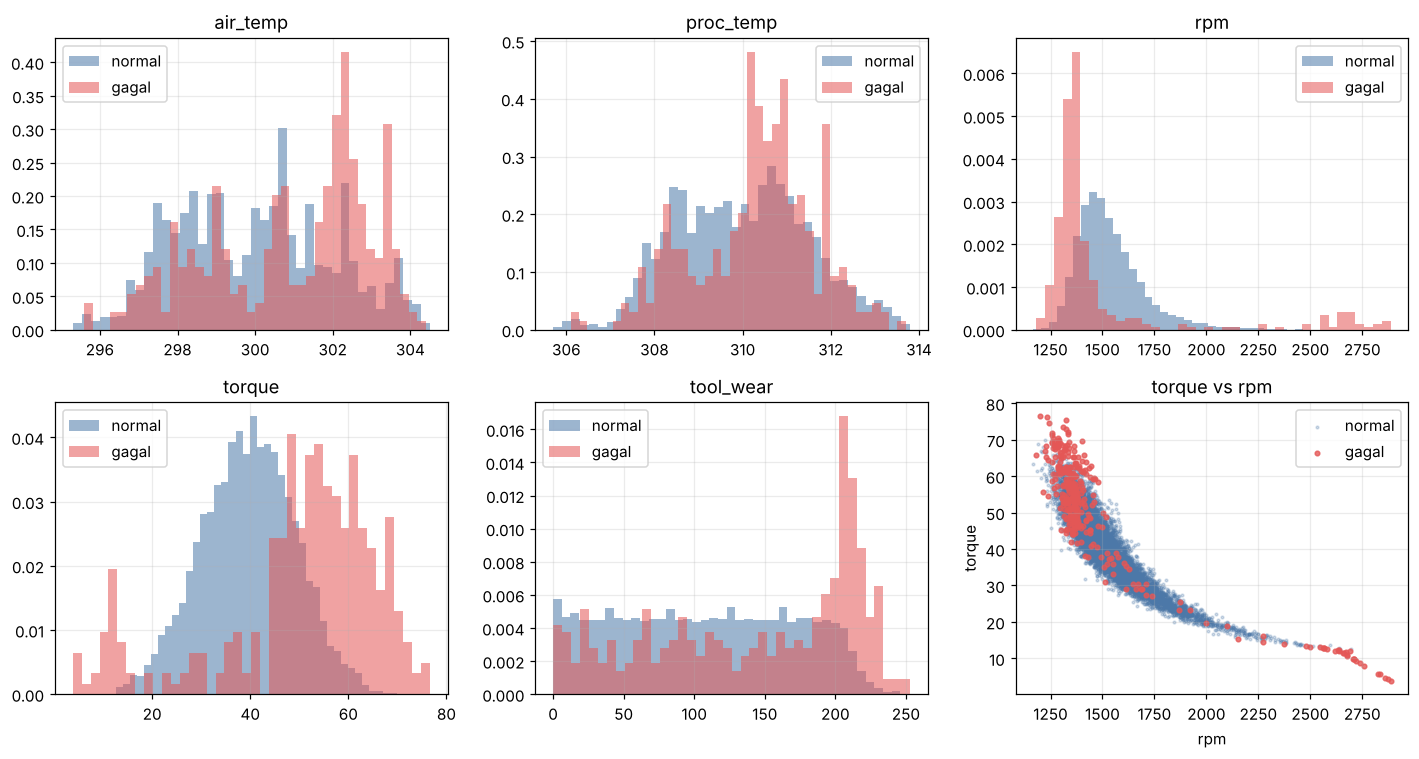

In [7]:
# 2.5 Visualisasi distribusi normal vs gagal
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), NUM):
    for lab, col, nm in [(0, "#4c78a8", "normal"), (1, "#e45756", "gagal")]:
        ax.hist(df.loc[df.machine_failure == lab, c], bins=40, density=True,
                alpha=.55, color=col, label=nm)
    ax.set_title(c); ax.legend()
ax = axes.ravel()[5]
nrm, flr = df[df.machine_failure == 0], df[df.machine_failure == 1]
ax.scatter(nrm.rpm, nrm.torque, s=3, alpha=.25, c="#4c78a8", label="normal")
ax.scatter(flr.rpm, flr.torque, s=9, alpha=.8, c="#e45756", label="gagal")
ax.set_xlabel("rpm"); ax.set_ylabel("torque"); ax.set_title("torque vs rpm"); ax.legend()
plt.tight_layout(); savefig("w2_distribusi"); plt.show()

,air_temp,proc_temp,rpm,torque,tool_wear,machine_failure
air_temp,1.00,0.88,0.02,-0.01,0.01,0.08
proc_temp,0.88,1.00,0.02,-0.01,0.01,0.04
rpm,0.02,0.02,1.00,-0.88,0.00,-0.04
torque,-0.01,-0.01,-0.88,1.00,-0.00,0.19
tool_wear,0.01,0.01,0.00,-0.00,1.00,0.11
machine_failure,0.08,0.04,-0.04,0.19,0.11,1.00


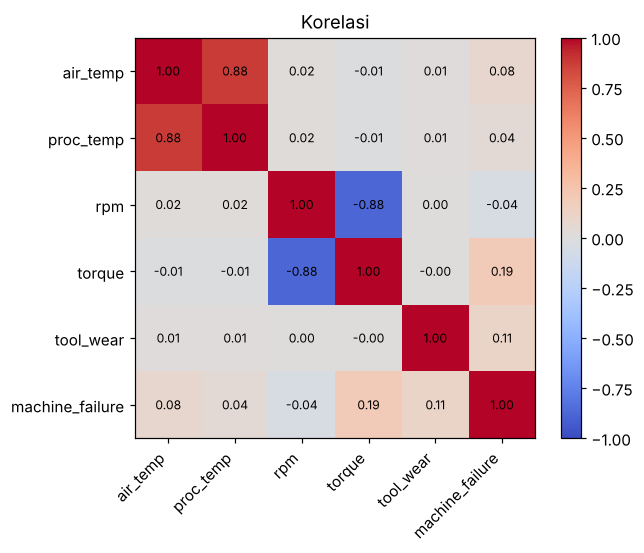

Pencilan IQR per fitur (pencilan statistik belum tentu anomali proses)


,n_pencilan_IQR,persen,rasio_gagal_pada_pencilan,rasio_gagal_keseluruhan
fitur,,,,
air_temp,0,0.00,NaN,0.034
proc_temp,0,0.00,NaN,0.034
rpm,418,4.18,0.084,0.034
torque,69,0.69,0.899,0.034
tool_wear,0,0.00,NaN,0.034


In [8]:
# 2.6 Korelasi dan pencilan
cols = NUM + ["machine_failure"]
corr = df[cols].corr().round(2)
display(corr)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Korelasi"); plt.tight_layout(); savefig("w2_korelasi"); plt.show()

rows = []
base_rate = df.machine_failure.mean()
for c in NUM:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    out = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)
    rows.append(dict(fitur=c, n_pencilan_IQR=int(out.sum()), persen=round(out.mean() * 100, 2),
                     rasio_gagal_pada_pencilan=round(df.loc[out, "machine_failure"].mean(), 3) if out.any() else np.nan,
                     rasio_gagal_keseluruhan=round(base_rate, 3)))
print("Pencilan IQR per fitur (pencilan statistik belum tentu anomali proses)")
display(pd.DataFrame(rows).set_index("fitur"))

In [9]:
# 2.6b Ringkasan numerik pola pada histogram (dasar interpretasi EDA di laporan)
nrm, flr = df[df.machine_failure == 0], df[df.machine_failure == 1]
inc = df[(df.machine_failure == 0) & (df[MODES].sum(axis=1) > 0)]
print("Baris mode aktif tetapi failure=0, per mode:", inc[MODES].sum().to_dict())
td = lambda x: x.proc_temp - x.air_temp
rows = [
    ("rpm < 1380", (flr.rpm < 1380).mean(), (nrm.rpm < 1380).mean()),
    ("tool_wear >= 200", (flr.tool_wear >= 200).mean(), (nrm.tool_wear >= 200).mean()),
    ("temp_diff < 8.6 K", (td(flr) < 8.6).mean(), (td(nrm) < 8.6).mean()),
    ("torque > 50 Nm", (flr.torque > 50).mean(), (nrm.torque > 50).mean()),
]
display(pd.DataFrame(rows, columns=["kondisi", "proporsi_gagal", "proporsi_normal"]).set_index("kondisi").round(3))
print("Jumlah siklus gagal dengan rpm > 2000:", int((flr.rpm > 2000).sum()),
      "| dengan torque < 20 Nm:", int((flr.torque < 20).sum()))
print("Rata-rata air_temp: gagal %.2f K vs normal %.2f K; khusus HDF %.2f K" %
      (flr.air_temp.mean(), nrm.air_temp.mean(), df[df.hdf == 1].air_temp.mean()))

Baris mode aktif tetapi failure=0, per mode: {'twf': 0, 'hdf': 0, 'pwf': 0, 'osf': 0, 'rnf': 18}


,proporsi_gagal,proporsi_normal
kondisi,,
rpm < 1380,0.643,0.118
tool_wear >= 200,0.363,0.070
temp_diff < 8.6 K,0.372,0.061
torque > 50 Nm,0.622,0.138


Jumlah siklus gagal dengan rpm > 2000: 33 | dengan torque < 20 Nm: 34
Rata-rata air_temp: gagal 300.89 K vs normal 299.97 K; khusus HDF 302.56 K


In [10]:
# 2.7 Preprocessing dan fitur turunan
d = df.copy().reset_index(drop=True)
d["type_ord"] = d["type"].map({"L": 0, "M": 1, "H": 2})
d["temp_diff"] = d["proc_temp"] - d["air_temp"]
d["power_w"] = d["torque"] * d["rpm"] * 2 * np.pi / 60
d["wear_torque"] = d["tool_wear"] * d["torque"]

FEATS = {
    "RAW": ["type_ord", "air_temp", "proc_temp", "rpm", "torque", "tool_wear"],
    "ENG": ["type_ord", "air_temp", "proc_temp", "rpm", "torque", "tool_wear",
            "temp_diff", "power_w", "wear_torque"],
}
y = d["machine_failure"].values.astype(int)

assert not set(MODES) & set(FEATS["ENG"]), "Kolom label bocor ke fitur!"
assert d[FEATS["ENG"]].isna().sum().sum() == 0

# ukuran efek (Cohen's d): seberapa jauh rata-rata kelas gagal dari kelas normal
eff = []
for c in FEATS["ENG"]:
    a, b = d.loc[y == 1, c], d.loc[y == 0, c]
    sp_ = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    eff.append(dict(fitur=c, mean_normal=b.mean(), mean_gagal=a.mean(), cohen_d=(a.mean() - b.mean()) / sp_))
eff = pd.DataFrame(eff).set_index("fitur").round(3)
display(eff.sort_values("cohen_d", key=abs, ascending=False))
d.to_csv(OUT / "data_preprocessed.csv", index=False)
print("Disimpan: outputs/data_preprocessed.csv")

,mean_normal,mean_gagal,cohen_d
fitur,,,
torque,39.630,50.168,1.077
wear_torque,4213.843,7187.938,1.072
power_w,6244.548,7282.819,0.988
temp_diff,10.022,9.404,-0.621
tool_wear,106.694,143.782,0.586
air_temp,299.974,300.886,0.458
rpm,1540.260,1496.487,-0.244
type_ord,0.505,0.369,-0.203
proc_temp,309.996,310.290,0.199


Disimpan: outputs/data_preprocessed.csv


**Catatan Minggu 2 – temuan dari EDA dan preprocessing**
- **Ketidakseimbangan kelas:** hanya 339 dari 10.000 siklus (3,39%) yang gagal. Model "selalu normal" sudah 96,6% akurat sehingga akurasi tidak bisa dipakai; evaluasi harus berbasis kurva precision–recall.
- **Kualitas data baik:** tidak ada nilai hilang, tidak ada duplikat, dan semua nilai lolos pemeriksaan kewajaran fisik (suhu proses selalu di atas suhu udara, torsi/rpm positif). Karena itu tidak ada imputasi atau penghapusan baris.
- **Label tidak 100% konsisten (27 baris):** 9 baris `machine_failure = 1` tanpa satu pun mode aktif, dan 18 baris dengan mode aktif tetapi `machine_failure = 0` — **seluruh 18 baris itu adalah RNF**. Pada Milestone 1 label `machine_failure` dipakai apa adanya; perlakuan khusus dijadwalkan untuk UAS.
- **Aturan pembangkitan terverifikasi:** HDF, PWF, dan OSF cocok 100% dengan aturan dokumentasi (115/115, 95/95, 98/98 baris). TWF hanya memiliki *jendela peluang* (790 baris memenuhi 200–240 menit, tetapi hanya 46 yang berlabel TWF), dan RNF acak murni. Ini memprediksi bahwa TWF dan RNF akan sulit dideteksi dari parameter proses.
- **Pola pada histogram:** siklus gagal terkonsentrasi pada rpm rendah (64% kasus gagal memiliki rpm < 1380, dibanding 12% pada kasus normal), torsi tinggi (> 50 Nm) tetapi juga ada kelompok kecil torsi sangat rendah (< 20 Nm) dengan rpm sangat tinggi (> 2000) — keduanya ujung kurva daya (PWF). Keausan pahat ≥ 200 menit muncul pada 36% kasus gagal vs 7% kasus normal. Suhu udara pada kasus gagal sedikit bergeser ke atas (HDF).
- **Korelasi:** rpm dan torsi berkorelasi kuat negatif (−0,88), suhu udara dan suhu proses kuat positif (0,88). Korelasi linear setiap fitur dengan label lemah (|r| ≤ 0,19), artinya kegagalan tidak terpisah oleh satu fitur secara linear, melainkan oleh **kombinasi** fitur — alasan memakai detektor multivariat dan fitur turunan.
- **Pencilan IQR ≠ dibuang:** 69 pencilan torsi memiliki rasio gagal 89,9% (vs 3,4% keseluruhan) dan 418 pencilan rpm 8,4%. Pencilan justru sinyal anomali, sehingga **tidak dihapus**.
- **Ukuran efek (Cohen's d):** pemisah terkuat adalah `torque` (1,08), `wear_torque` (1,07), dan `power_w` (0,99). Dua dari tiga teratas adalah fitur turunan, mendukung H1.
- **Preprocessing:** `type` dikodekan ordinal (L=0, M=1, H=2) karena memang tingkatan kualitas. Fitur distandardisasi (`StandardScaler`) karena semua detektor yang dipakai berbasis jarak/varians dan skala fitur sangat berbeda (K, rpm, Nm, menit, W); scaler di-*fit* hanya pada data *fit* per seed (bagian 3.2), sehingga statistik validasi/uji tidak bocor.
- `temp_diff = proc_temp − air_temp` adalah kombinasi linear dua fitur lain. Untuk model linear (Mahalanobis/PCA) ia tidak menambah informasi baru (bahkan membuat matriks kovarians hampir singular); untuk model berbasis jarak/kepadatan ia mengubah geometri ruang fitur.
- *Catatan kejujuran:* statistik EDA di atas dihitung pada seluruh data (termasuk bagian yang nanti menjadi data uji). Statistik ini hanya dipakai untuk memahami data dan merancang fitur, tidak dipakai untuk melatih model atau memilih ambang.

---
# Minggu 3 · Baseline & Evaluasi Awal

**Pembagian data (stratified menurut `machine_failure`):** 60% *fit* · 20% *validasi* · 20% *uji*.

| Bagian | Dipakai untuk |
|---|---|
| **fit** | melatih model (unsup: semua baris tanpa label; semi: hanya baris normal) |
| **validasi** | menetapkan **ambang** (persentil ke-(1−p) skor validasi, p = proporsi gagal di data latih) **dan memilih model/hiperparameter** |
| **uji** | pelaporan akhir saja |

**Metrik:** PR-AUC (utama), ROC-AUC, precision / recall / F1 pada ambang di atas. Skor acak memberi PR-AUC ≈ proporsi kelas gagal.
**Stabilitas:** semua eksperimen diulang pada 5 seed pembagian data (rata-rata ± simpangan baku).

In [11]:
# 3.1 Pembagian data
def build_splits(seed):
    idx = np.arange(len(d))
    tr_all, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
    fit, val = train_test_split(tr_all, test_size=0.25, stratify=y[tr_all], random_state=seed)
    return dict(tr_all=tr_all, fit=fit, val=val, te=te)

SPLITS = {s: build_splits(s) for s in SEEDS}
sp = SPLITS[SEED]
print({k: (len(v), f"{y[v].mean():.2%} gagal") for k, v in sp.items()})
assert len(set(sp["fit"]) & set(sp["val"])) == 0 and len(set(sp["tr_all"]) & set(sp["te"])) == 0
print("Rata-rata baris normal pada data fit (skenario semi, 5 seed):", np.mean([(y[SPLITS[s]['fit']] == 0).sum() for s in SEEDS]))

{'tr_all': (8000, '3.39% gagal'), 'fit': (6000, '3.38% gagal'), 'val': (2000, '3.40% gagal'), 'te': (2000, '3.40% gagal')}
Rata-rata baris normal pada data fit (skenario semi, 5 seed): 5797.0


In [12]:
# 3.2 Mesin evaluasi (dipakai di semua tahap berikutnya)
def get_data(feats, scenario, seed, frac=1.0):
    """Standardisasi di-fit hanya pada data fit. semi -> hanya baris normal."""
    s = SPLITS[seed]
    fit_idx = s["fit"] if scenario == "unsup" else s["fit"][y[s["fit"]] == 0]
    if frac < 1.0:
        rng = np.random.default_rng(seed)
        fit_idx = rng.choice(fit_idx, size=max(int(len(fit_idx) * frac), 20), replace=False)
    A = d[feats].values.astype(float)
    sc = StandardScaler().fit(A[fit_idx])
    return sc.transform(A[fit_idx]), sc.transform(A[s["val"]]), sc.transform(A[s["te"]])

def evaluate(s_val, s_te, seed, prior_mult=1.0):
    """Ambang dari validasi: persentil (1-p) skor validasi; p = prior gagal pada data latih."""
    s = SPLITS[seed]
    yv, yt = y[s["val"]], y[s["te"]]
    p = min(y[s["tr_all"]].mean() * prior_mult, 0.5)
    thr = np.quantile(s_val, 1 - p)
    pred = (s_te > thr).astype(int)
    return dict(val_pr_auc=average_precision_score(yv, s_val), val_roc_auc=roc_auc_score(yv, s_val),
                roc_auc=roc_auc_score(yt, s_te), pr_auc=average_precision_score(yt, s_te),
                precision=precision_score(yt, pred, zero_division=0),
                recall=recall_score(yt, pred, zero_division=0),
                f1=f1_score(yt, pred, zero_division=0), n_alarm=int(pred.sum()))

METRICS = ["roc_auc", "pr_auc", "precision", "recall", "f1"]

In [13]:
# 3.3 Model: semua menghasilkan skor anomali (makin besar = makin anomali)
DEFAULTS = {
    "Mahalanobis": {},
    "PCA reconstruction": {"n_components": 0.95},
    "Isolation Forest": {"n_estimators": 300, "max_samples": "auto", "max_features": 1.0},
    "LOF": {"n_neighbors": 35},
    "One-Class SVM": {"nu": 0.05, "gamma": "scale"},
    "Autoencoder (MLP)": {"hidden": (16, 3, 16), "alpha": 1e-4},
}
BASELINES = ["Acak (baseline)", "Z-score maks (baseline)"]
CANDIDATES = list(DEFAULTS)

def fit_score(name, Xfit, Xval, Xte, seed, **kw):
    """Mengembalikan (skor_validasi, skor_uji)."""
    p = {**DEFAULTS.get(name, {}), **kw}
    if name == "Acak (baseline)":
        rng = np.random.default_rng(seed)
        return rng.random(len(Xval)), rng.random(len(Xte))
    if name == "Z-score maks (baseline)":
        f = lambda X: np.abs(X).max(axis=1)
        return f(Xval), f(Xte)
    if name == "Mahalanobis":
        m = EmpiricalCovariance().fit(Xfit)
        return m.mahalanobis(Xval), m.mahalanobis(Xte)
    if name == "PCA reconstruction":
        m = PCA(n_components=p["n_components"], random_state=seed).fit(Xfit)
        f = lambda X: ((X - m.inverse_transform(m.transform(X))) ** 2).sum(axis=1)
        return f(Xval), f(Xte)
    if name == "Isolation Forest":
        m = IsolationForest(n_estimators=p["n_estimators"], max_samples=p["max_samples"],
                            max_features=p["max_features"], random_state=seed, n_jobs=-1).fit(Xfit)
        return -m.score_samples(Xval), -m.score_samples(Xte)
    if name == "LOF":
        m = LocalOutlierFactor(n_neighbors=p["n_neighbors"], novelty=True, n_jobs=-1).fit(Xfit)
        return -m.score_samples(Xval), -m.score_samples(Xte)
    if name == "One-Class SVM":
        m = OneClassSVM(kernel="rbf", gamma=p["gamma"], nu=p["nu"]).fit(Xfit)
        return -m.score_samples(Xval), -m.score_samples(Xte)
    if name == "Autoencoder (MLP)":
        m = MLPRegressor(hidden_layer_sizes=p["hidden"], alpha=p["alpha"], max_iter=300,
                         early_stopping=True, random_state=seed).fit(Xfit, Xfit)
        f = lambda X: ((X - m.predict(X)) ** 2).mean(axis=1)
        return f(Xval), f(Xte)
    raise ValueError(name)

def run_grid(models, fkeys, scens, seeds, params=None):
    params = params or {}
    rows = []
    for seed in seeds:
        for fk in fkeys:
            for sc in scens:
                Xf, Xv, Xt = get_data(FEATS[fk], sc, seed)
                for m in models:
                    s_val, s_te = fit_score(m, Xf, Xv, Xt, seed, **params.get(m, {}))
                    rows.append(dict(seed=seed, fitur=fk, skenario=sc, model=m, **evaluate(s_val, s_te, seed)))
    return pd.DataFrame(rows)

In [14]:
# 3.4 Baseline
res_base = run_grid(BASELINES, list(FEATS), ["unsup", "semi"], SEEDS)
prev = y.mean()
print(f"Acuan: PR-AUC skor acak ≈ proporsi kelas gagal = {prev:.3f}")
print(f"Akurasi model 'selalu prediksi normal' = {1 - prev:.3f} (tinggi tetapi tidak mendeteksi apa pun)\n")
display(res_base.groupby(["model", "fitur", "skenario"])[METRICS].agg(["mean", "std"]).round(3))

Acuan: PR-AUC skor acak ≈ proporsi kelas gagal = 0.034
Akurasi model 'selalu prediksi normal' = 0.966 (tinggi tetapi tidak mendeteksi apa pun)



roc_auc        pr_auc        precision        recall            f1       
                                          mean    std   mean    std      mean    std   mean    std   mean    std
model                   fitur skenario                                                                          
Acak (baseline)         ENG   semi       0.493  0.040  0.042  0.011     0.049  0.007  0.050  0.008  0.050  0.008
                              unsup      0.493  0.040  0.042  0.011     0.049  0.007  0.050  0.008  0.050  0.008
                        RAW   semi       0.493  0.040  0.042  0.011     0.049  0.007  0.050  0.008  0.050  0.008
                              unsup      0.493  0.040  0.042  0.011     0.049  0.007  0.050  0.008  0.050  0.008
Z-score maks (baseline) ENG   semi       0.860  0.030  0.310  0.079     0.379  0.083  0.376  0.101  0.376  0.088
                              unsup      0.852  0.029  0.298  0.077     0.364  0.075  0.356  0.084  0.358  0.076
                        RAW   semi       0.781  0.029  0.212  0.068     0.256  0.088  0.247  0.071  0.250  0.077
                              unsup      0.767  0.030  0.200  0.064     0.255  0.070  0.247  0.079  0.250  0.073

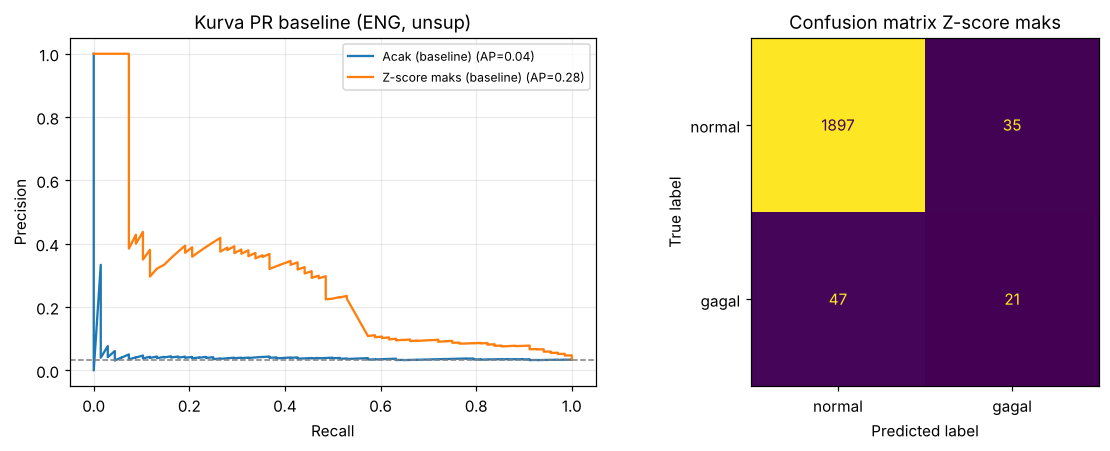

In [15]:
# 3.5 Kurva PR dan confusion matrix baseline (seed utama)
Xf, Xv, Xt = get_data(FEATS["ENG"], "unsup", SEED)
yte = y[SPLITS[SEED]["te"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for nm in BASELINES:
    s_val, s_te = fit_score(nm, Xf, Xv, Xt, SEED)
    pr, rc, _ = precision_recall_curve(yte, s_te)
    axes[0].plot(rc, pr, label=f"{nm} (AP={average_precision_score(yte, s_te):.2f})")
axes[0].axhline(yte.mean(), color="gray", ls="--", lw=1)
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Kurva PR baseline (ENG, unsup)")
axes[0].legend(fontsize=8)
s_val, s_te = fit_score("Z-score maks (baseline)", Xf, Xv, Xt, SEED)
thr = np.quantile(s_val, 1 - y[SPLITS[SEED]["tr_all"]].mean())
ConfusionMatrixDisplay.from_predictions(yte, (s_te > thr).astype(int), display_labels=["normal", "gagal"],
                                        ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix Z-score maks"); axes[1].grid(False)
plt.tight_layout(); savefig("w3_baseline"); plt.show()

**Catatan Minggu 3:**
- Baseline **Acak** memberi PR-AUC 0,042 ≈ proporsi kelas gagal (0,034) dan ROC-AUC ≈ 0,49, sesuai teori — ini memastikan mesin evaluasi bekerja benar.
- Baseline **Z-score maks** (nilai |z| terbesar di antara fitur) sudah jauh di atas acak: PR-AUC 0,310 (ENG, semi), 7× lipat acak. Artinya sebagian besar kegagalan memang berupa nilai ekstrem pada satu fitur.
- Dengan fitur mentah (RAW) Z-score maks turun ke 0,200–0,212; fitur turunan sudah membantu bahkan pada baseline.
- Pada confusion matrix (ENG, unsup, seed 42): 21 dari 68 kegagalan terdeteksi dengan 35 alarm palsu dari 1.932 siklus normal.
- Model yang diusulkan harus **mengalahkan Z-score maks**, bukan hanya skor acak, agar kompleksitas model dapat dibenarkan.

---
# Minggu 4 · Kandidat Model & Perbandingan

| Model | Jenis | Skor anomali |
|---|---|---|
| Mahalanobis | statistik multivariat | jarak Mahalanobis |
| PCA reconstruction | rekonstruksi linear | galat rekonstruksi |
| Isolation Forest | berbasis pohon | −`score_samples` |
| LOF | kepadatan lokal | −`score_samples` (*novelty*) |
| One-Class SVM | batas kernel | −`score_samples` |
| Autoencoder (MLP) | rekonstruksi non-linear | galat kuadrat rata-rata |

Hiperparameter masih **bawaan** pada tahap ini. Penyetelan dilakukan di Minggu 5–7. Konfigurasi (fitur, skenario) dan kandidat unggulan dipilih dengan **PR-AUC validasi**, bukan data uji.

**Alasan pemilihan kandidat:** keenam model mewakili keluarga deteksi anomali yang berbeda (statistik parametrik, rekonstruksi linear, isolasi berbasis pohon, kepadatan lokal, batas kernel, rekonstruksi non-linear), semuanya tersedia di scikit-learn (*classical ML*) dan dapat dilatih tanpa label. Dengan begitu kita bisa melihat asumsi bentuk data mana yang paling cocok dengan kegagalan pada AI4I 2020.

In [16]:
# 4.1 Menjalankan semua kandidat (beberapa menit)
t0 = time.time()
res_cand = run_grid(CANDIDATES, list(FEATS), ["unsup", "semi"], SEEDS)
res = pd.concat([res_base, res_cand], ignore_index=True)
MODEL_NAMES = BASELINES + CANDIDATES
print("Selesai dalam", round(time.time() - t0), "detik | baris hasil:", res.shape)

Selesai dalam 39 detik | baris hasil: (160, 12)


In [17]:
# 4.2 Tabel perbandingan
print("PR-AUC uji (rata-rata 5 seed)")
display(res.pivot_table(index="model", columns=["fitur", "skenario"], values="pr_auc").loc[MODEL_NAMES].round(3))
print("ROC-AUC uji (rata-rata 5 seed)")
display(res.pivot_table(index="model", columns=["fitur", "skenario"], values="roc_auc").loc[MODEL_NAMES].round(3))

PR-AUC uji (rata-rata 5 seed)


fitur                      ENG           RAW       
skenario                  semi  unsup   semi  unsup
model                                              
Acak (baseline)          0.042  0.042  0.042  0.042
Z-score maks (baseline)  0.310  0.298  0.212  0.200
Mahalanobis              0.334  0.327  0.282  0.268
PCA reconstruction       0.252  0.250  0.285  0.281
Isolation Forest         0.274  0.288  0.135  0.150
LOF                      0.464  0.295  0.340  0.206
One-Class SVM            0.434  0.300  0.341  0.239
Autoencoder (MLP)        0.049  0.047  0.099  0.049

ROC-AUC uji (rata-rata 5 seed)


fitur                      ENG           RAW       
skenario                  semi  unsup   semi  unsup
model                                              
Acak (baseline)          0.493  0.493  0.493  0.493
Z-score maks (baseline)  0.860  0.852  0.781  0.767
Mahalanobis              0.876  0.864  0.854  0.840
PCA reconstruction       0.792  0.786  0.814  0.805
Isolation Forest         0.871  0.863  0.797  0.785
LOF                      0.901  0.869  0.870  0.839
One-Class SVM            0.873  0.825  0.826  0.766
Autoencoder (MLP)        0.613  0.584  0.703  0.617

In [18]:
# 4.3 Pemilihan konfigurasi dan shortlist berdasarkan VALIDASI
nb = res[~res.model.str.contains("baseline")]
cfg_val = nb.groupby(["fitur", "skenario"]).val_pr_auc.mean().sort_values(ascending=False)
BEST_FEAT, BEST_SCEN = cfg_val.index[0]
print("Rata-rata PR-AUC validasi per konfigurasi (non-baseline):")
print(cfg_val.round(3).to_string())
print(f"\nKonfigurasi terpilih (validasi): fitur={BEST_FEAT}, skenario={BEST_SCEN}")

rank = (nb[(nb.fitur == BEST_FEAT) & (nb.skenario == BEST_SCEN)]
        .groupby("model")[["val_pr_auc", "pr_auc", "roc_auc", "precision", "recall", "f1"]].mean()
        .sort_values("val_pr_auc", ascending=False).round(3))
display(rank)
SHORTLIST = list(rank.index[:3])
print("Shortlist kandidat (3 teratas menurut PR-AUC validasi):", SHORTLIST)

Rata-rata PR-AUC validasi per konfigurasi (non-baseline):
fitur  skenario
ENG    semi        0.281
       unsup       0.240
RAW    semi        0.227
       unsup       0.189

Konfigurasi terpilih (validasi): fitur=ENG, skenario=semi


,val_pr_auc,pr_auc,roc_auc,precision,recall,f1
model,,,,,,
LOF,0.454,0.464,0.901,0.447,0.503,0.470
One-Class SVM,0.422,0.434,0.873,0.408,0.459,0.429
Mahalanobis,0.298,0.334,0.876,0.365,0.382,0.371
PCA reconstruction,0.236,0.252,0.792,0.304,0.294,0.293
Isolation Forest,0.230,0.274,0.871,0.291,0.332,0.306
Autoencoder (MLP),0.043,0.049,0.613,0.032,0.035,0.033


Shortlist kandidat (3 teratas menurut PR-AUC validasi): ['LOF', 'One-Class SVM', 'Mahalanobis']


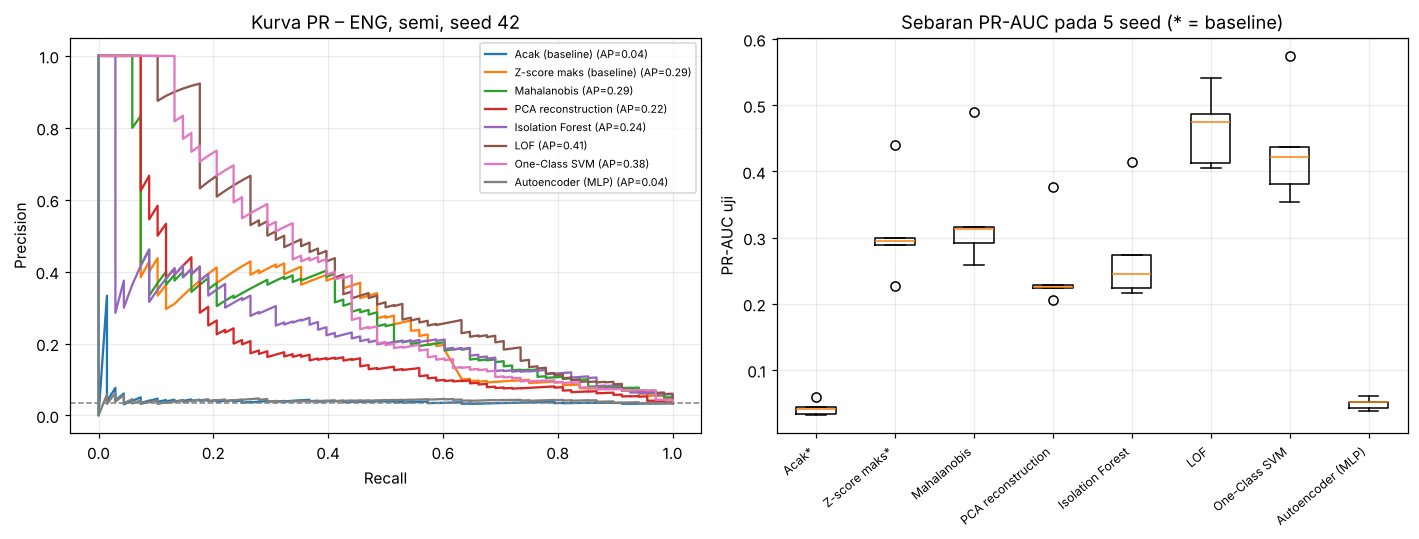

In [19]:
# 4.4 Kurva PR, ROC-AUC per seed
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
Xf, Xv, Xt = get_data(FEATS[BEST_FEAT], BEST_SCEN, SEED)
yte = y[SPLITS[SEED]["te"]]
for nm in MODEL_NAMES:
    _, s_te = fit_score(nm, Xf, Xv, Xt, SEED)
    pr, rc, _ = precision_recall_curve(yte, s_te)
    axes[0].plot(rc, pr, lw=1.5, label=f"{nm} (AP={average_precision_score(yte, s_te):.2f})")
axes[0].axhline(yte.mean(), color="gray", ls="--", lw=1)
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title(f"Kurva PR – {BEST_FEAT}, {BEST_SCEN}, seed {SEED}"); axes[0].legend(fontsize=7)

sub = res[(res.fitur == BEST_FEAT) & (res.skenario == BEST_SCEN)]
data = [sub[sub.model == m].pr_auc.values for m in MODEL_NAMES]
axes[1].boxplot(data)
axes[1].set_xticks(range(1, len(MODEL_NAMES) + 1))
axes[1].set_xticklabels([m.replace(" (baseline)", "*") for m in MODEL_NAMES])
axes[1].set_ylabel("PR-AUC uji"); axes[1].set_title("Sebaran PR-AUC pada 5 seed (* = baseline)")
plt.setp(axes[1].get_xticklabels(), rotation=40, ha="right", fontsize=8)
plt.tight_layout(); savefig("w4_perbandingan"); plt.show()

**Catatan Minggu 4:**
- **Konfigurasi terbaik (validasi): fitur ENG + skenario semi** (rata-rata PR-AUC validasi 0,281, vs 0,189 untuk RAW + unsup).
- **Terhadap baseline:** pada ENG-semi dengan hiperparameter bawaan, **LOF (PR-AUC uji 0,464)** dan **One-Class SVM (0,434)** jauh mengalahkan Z-score maks (0,310). Mahalanobis (0,334) hanya sedikit di atas baseline. PCA reconstruction (0,252), Isolation Forest (0,274), dan Autoencoder (0,049) **kalah** dari baseline Z-score.
- **Model kompleks belum tentu lebih baik:** Autoencoder bawaan (bottleneck 3) hampir setara skor acak. Kemungkinan karena bottleneck terlalu sempit/latihan belum konvergen sehingga galat rekonstruksi tidak membedakan normal dan gagal — diperiksa di penyetelan (E2).
- **Kestabilan:** sebaran PR-AUC antar-seed cukup lebar (boxplot), mis. LOF 0,41–0,54. Seed 46 konsisten memberi nilai tertinggi untuk hampir semua model, jadi selisih antar-model harus dibandingkan secara berpasangan per seed, bukan dari satu seed.
- **ROC-AUC menyesatkan:** Isolation Forest punya ROC-AUC 0,871 (hampir setara Mahalanobis 0,876) tetapi PR-AUC-nya lebih rendah. Pada data tidak seimbang ROC-AUC terlihat bagus karena didominasi kelas normal; inilah alasan PR-AUC dijadikan metrik utama.

---
# Minggu 5–7 · Eksperimen Awal

| Eksperimen | Pertanyaan | Dasar pemilihan |
|---|---|---|
| E1 Ablasi fitur & skenario | Menjawab RQ1 dan RQ2 | selisih berpasangan per seed |
| E2 Penyetelan hiperparameter awal (grid kecil) | Berapa kenaikan dari bawaan? | PR-AUC **validasi** |
| E3 Ensemble sederhana | Apakah gabungan model lebih baik? | PR-AUC **validasi** |
| E4 Analisis galat awal | Menjawab RQ3: mode/tipe mana yang lolos? | recall per mode |
| E5 Kepentingan fitur | Fitur mana yang menggerakkan skor? | permutasi pada validasi |

*Dipindah ke rencana UAS (bagian 6.6):* sensitivitas ambang & ambang berbasis biaya, perbandingan dengan batas atas klasifikasi berlabel, dan pengaruh ukuran data latih.

RQ1: selisih PR-AUC (ENG − RAW), berpasangan per seed dan skenario


,rata2,std,menang
model,,,
Autoencoder (MLP),-0.026,0.042,3/10
Isolation Forest,0.138,0.032,10/10
LOF,0.107,0.021,10/10
Mahalanobis,0.055,0.020,10/10
One-Class SVM,0.077,0.021,10/10
PCA reconstruction,-0.032,0.008,0/10


RQ2: selisih PR-AUC (semi − unsup), berpasangan per seed dan fitur


,rata2,std,menang
model,,,
Autoencoder (MLP),0.026,0.047,8/10
Isolation Forest,-0.014,0.012,1/10
LOF,0.152,0.026,10/10
Mahalanobis,0.011,0.009,8/10
One-Class SVM,0.118,0.021,10/10
PCA reconstruction,0.003,0.004,7/10



Semua model: ENG−RAW rata-rata +0.053 (menang 72%) | semi−unsup rata-rata +0.049 (menang 73%)


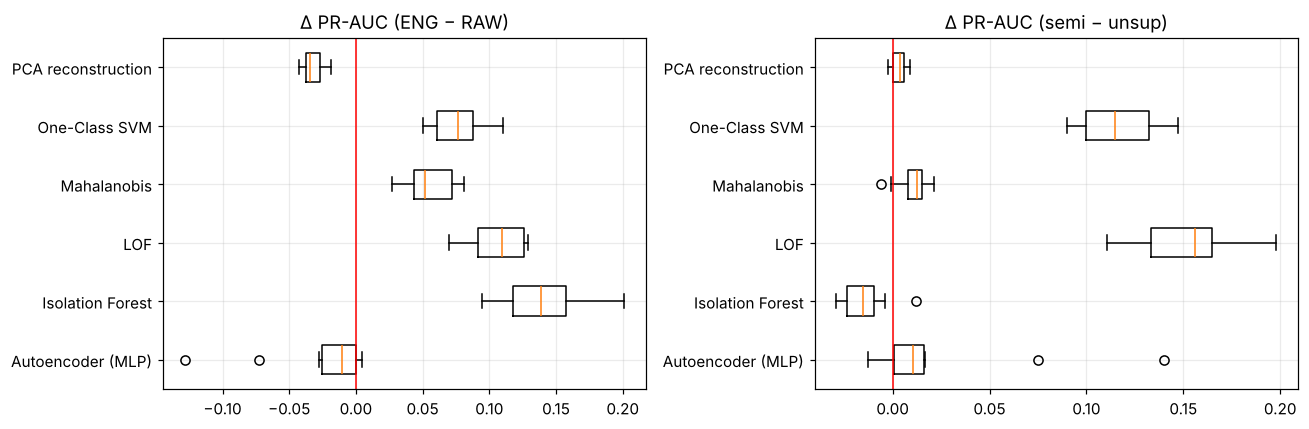

In [20]:
# E1 Ablasi fitur dan skenario (RQ1, RQ2)
def paired_delta(res_, factor, a, b, metric="pr_auc"):
    keys = [c for c in ["seed", "fitur", "skenario", "model"] if c != factor]
    pv = res_.pivot_table(index=keys, columns=factor, values=metric)
    return (pv[a] - pv[b]).rename("delta").reset_index()

nb = res[~res.model.str.contains("baseline")]
d1 = paired_delta(nb, "fitur", "ENG", "RAW")
d2 = paired_delta(nb, "skenario", "semi", "unsup")
summ = lambda dd: dd.groupby("model").delta.agg(rata2="mean", std="std",
                                                 menang=lambda s: f"{int((s > 0).sum())}/{len(s)}").round(3)
print("RQ1: selisih PR-AUC (ENG − RAW), berpasangan per seed dan skenario")
display(summ(d1))
print("RQ2: selisih PR-AUC (semi − unsup), berpasangan per seed dan fitur")
display(summ(d2))
H1_MEAN, H1_WIN = d1.delta.mean(), (d1.delta > 0).mean()
H2_MEAN, H2_WIN = d2.delta.mean(), (d2.delta > 0).mean()
print(f"\nSemua model: ENG−RAW rata-rata {H1_MEAN:+.3f} (menang {H1_WIN:.0%}) | "
      f"semi−unsup rata-rata {H2_MEAN:+.3f} (menang {H2_WIN:.0%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dd, ttl in [(axes[0], d1, "Δ PR-AUC (ENG − RAW)"), (axes[1], d2, "Δ PR-AUC (semi − unsup)")]:
    ms = list(dd.model.unique())
    ax.boxplot([dd[dd.model == m].delta.values for m in ms], vert=False)
    ax.set_yticks(range(1, len(ms) + 1)); ax.set_yticklabels(ms)
    ax.axvline(0, color="red", lw=1); ax.set_title(ttl)
plt.tight_layout(); savefig("w5_ablasi"); plt.show()

PCA reconstruction   selesai (0 detik)


Isolation Forest     selesai (12 detik)


LOF                  selesai (22 detik)


One-Class SVM        selesai (37 detik)


Autoencoder (MLP)    selesai (82 detik)


,param_terbaik,val_PR_bawaan,val_PR_tuned,uji_PR_bawaan,uji_PR_tuned
model,,,,,
PCA reconstruction,{'n_components': 0.99},0.236,0.302,0.252,0.334
Isolation Forest,"{'max_samples': 1024, 'max_features': 0.5}",0.230,0.307,0.274,0.349
LOF,{'n_neighbors': 35},0.454,0.454,0.464,0.464
One-Class SVM,"{'nu': 0.01, 'gamma': 0.03}",0.422,0.464,0.434,0.466
Autoencoder (MLP),"{'hidden': (16, 6, 16), 'alpha': 0.0001}",0.043,0.301,0.049,0.334


Pemeriksaan tepi grid (parameter terbaik di batas grid → grid sebaiknya diperluas):
  PCA reconstruction: n_components = 0.99 berada di tepi grid [0.7, 0.8, 0.9, 0.95, 0.99]
  Isolation Forest: max_samples = 1024 berada di tepi grid [64, 256, 1024]
  Isolation Forest: max_features = 0.5 berada di tepi grid [0.5, 1.0]
  One-Class SVM: nu = 0.01 berada di tepi grid [0.01, 0.03, 0.05, 0.1, 0.2]
  Autoencoder (MLP): alpha = 0.0001 berada di tepi grid [0.0001, 0.01]


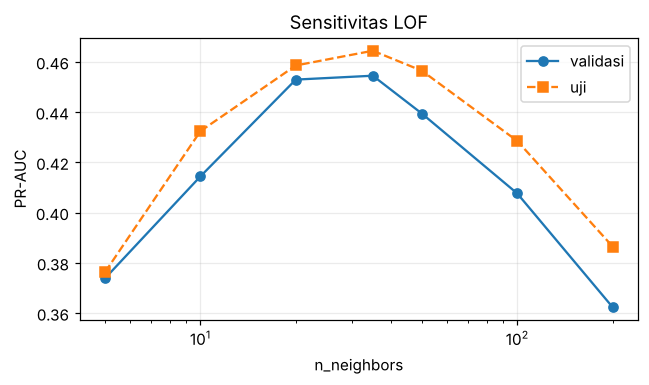

In [21]:
# E2 Penyetelan hiperparameter pada konfigurasi terpilih (kriteria = PR-AUC validasi)
GRIDS = {
    "PCA reconstruction": [{"n_components": c} for c in [0.7, 0.8, 0.9, 0.95, 0.99]],
    "Isolation Forest": [{"max_samples": ms, "max_features": mf} for ms in [64, 256, 1024] for mf in [0.5, 1.0]],
    "LOF": [{"n_neighbors": k} for k in [5, 10, 20, 35, 50, 100, 200]],
    "One-Class SVM": [{"nu": nu, "gamma": g} for nu in [0.01, 0.03, 0.05, 0.1, 0.2] for g in ["scale", 0.03, 0.1, 0.3]],
    "Autoencoder (MLP)": [{"hidden": h, "alpha": a} for h in [(16, 3, 16), (8, 2, 8), (32, 4, 32), (16, 6, 16)]
                          for a in [1e-4, 1e-2]],
}
DATA = {s: get_data(FEATS[BEST_FEAT], BEST_SCEN, s) for s in SEEDS}
PKEY = {}
rows, t0 = [], time.time()
for name, grid in GRIDS.items():
    for params in grid:
        key = repr(params); PKEY[(name, key)] = params
        for seed in SEEDS:
            Xf, Xv, Xt = DATA[seed]
            s_val, s_te = fit_score(name, Xf, Xv, Xt, seed, **params)
            rows.append(dict(model=name, params=key, seed=seed, **evaluate(s_val, s_te, seed)))
    print(f"{name:20s} selesai ({round(time.time() - t0)} detik)")
tune = pd.DataFrame(rows)
tune_sum = tune.groupby(["model", "params"])[["val_pr_auc", "pr_auc"]].mean()

BEST_PARAMS, tbl = {}, []
for name in GRIDS:
    sub = tune_sum.loc[name]
    bk = sub.val_pr_auc.idxmax()
    BEST_PARAMS[name] = PKEY[(name, bk)]
    dflt = res[(res.model == name) & (res.fitur == BEST_FEAT) & (res.skenario == BEST_SCEN)]
    tbl.append(dict(model=name, param_terbaik=bk, val_PR_bawaan=dflt.val_pr_auc.mean(),
                    val_PR_tuned=sub.val_pr_auc[bk], uji_PR_bawaan=dflt.pr_auc.mean(), uji_PR_tuned=sub.pr_auc[bk]))
tune_report = pd.DataFrame(tbl).set_index("model").round(3)
display(tune_report)

print("Pemeriksaan tepi grid (parameter terbaik di batas grid → grid sebaiknya diperluas):")
for name, grid in GRIDS.items():
    for k, v in BEST_PARAMS[name].items():
        uniq = []
        for g in grid:
            if g[k] not in uniq: uniq.append(g[k])
        if len(uniq) > 1 and all(isinstance(u, (int, float)) for u in uniq) and v in (min(uniq), max(uniq)):
            print(f"  {name}: {k} = {v} berada di tepi grid {uniq}")

lof = tune_sum.loc["LOF"].reset_index()
lof["k"] = [PKEY[("LOF", p)]["n_neighbors"] for p in lof.params]
lof = lof.sort_values("k")
plt.figure(figsize=(6, 3.6))
plt.plot(lof.k, lof.val_pr_auc, "o-", label="validasi"); plt.plot(lof.k, lof.pr_auc, "s--", label="uji")
plt.xscale("log"); plt.xlabel("n_neighbors"); plt.ylabel("PR-AUC"); plt.title("Sensitivitas LOF"); plt.legend()
plt.tight_layout(); savefig("w6_lof_sensitivitas"); plt.show()

In [22]:
# E3 Ensemble (rank-average) dari model hasil penyetelan
def rank_norm(s_val, s_te):
    """Normalisasi peringkat tanpa label: skor validasi+uji diberi peringkat gabungan (transduktif, tanpa label)."""
    allv = rankdata(np.concatenate([s_val, s_te])) / (len(s_val) + len(s_te))
    return allv[:len(s_val)], allv[len(s_val):]

TUNED = ["Mahalanobis"] + list(GRIDS)
SC = {}
for seed in SEEDS:
    Xf, Xv, Xt = DATA[seed]
    for name in TUNED:
        SC[(name, seed)] = fit_score(name, Xf, Xv, Xt, seed, **BEST_PARAMS.get(name, {}))

def cand_scores(members, seed):
    if len(members) == 1:
        return SC[(members[0], seed)]
    rv, rt = zip(*[rank_norm(*SC[(m, seed)]) for m in members])
    return np.mean(rv, axis=0), np.mean(rt, axis=0)

single_rank = (pd.DataFrame([dict(model=n, seed=s, **evaluate(*SC[(n, s)], s)) for n in TUNED for s in SEEDS])
               .groupby("model").val_pr_auc.mean().sort_values(ascending=False))
CAND = {n: [n] for n in TUNED}
for k in [2, 3, 4]:
    CAND[f"Ensemble top-{k}"] = list(single_rank.index[:k])

rows = [dict(kandidat=c, seed=s, **evaluate(*cand_scores(mem, s), s)) for c, mem in CAND.items() for s in SEEDS]
cand_df = pd.DataFrame(rows)
cand_tab = (cand_df.groupby("kandidat")[["val_pr_auc", "pr_auc", "roc_auc", "precision", "recall", "f1"]]
            .agg(["mean", "std"]).round(3))
display(cand_tab.sort_values(("val_pr_auc", "mean"), ascending=False))
for c, mem in CAND.items():
    if len(mem) > 1:
        print(f"{c}: {mem}")

val_pr_auc        pr_auc        roc_auc        precision        recall            f1       
                         mean    std   mean    std    mean    std      mean    std   mean    std   mean    std
kandidat                                                                                                      
Ensemble top-2          0.480  0.025  0.486  0.066   0.909  0.016     0.442  0.047  0.488  0.081  0.462  0.052
One-Class SVM           0.464  0.030  0.466  0.071   0.893  0.018     0.445  0.058  0.468  0.080  0.455  0.064
LOF                     0.454  0.020  0.464  0.056   0.901  0.018     0.447  0.048  0.503  0.079  0.470  0.052
Ensemble top-3          0.446  0.014  0.460  0.081   0.907  0.020     0.443  0.060  0.465  0.090  0.450  0.054
Ensemble top-4          0.438  0.021  0.462  0.078   0.906  0.021     0.446  0.061  0.468  0.102  0.449  0.044
Isolation Forest        0.307  0.016  0.349  0.087   0.888  0.027     0.349  0.060  0.379  0.148  0.354  0.081
PCA reconstruction      0.302  0.046  0.334  0.088   0.841  0.031     0.352  0.078  0.368  0.096  0.356  0.080
Autoencoder (MLP)       0.301  0.070  0.334  0.081   0.808  0.040     0.353  0.063  0.362  0.090  0.354  0.070
Mahalanobis             0.298  0.038  0.334  0.090   0.876  0.027     0.365  0.067  0.382  0.106  0.371  0.079

Ensemble top-2: ['One-Class SVM', 'LOF']
Ensemble top-3: ['One-Class SVM', 'LOF', 'Isolation Forest']
Ensemble top-4: ['One-Class SVM', 'LOF', 'Isolation Forest', 'PCA reconstruction']


In [23]:
# Pemilihan kandidat terbaik sementara (berdasarkan PR-AUC VALIDASI saja)
# Catatan: variabel FINAL = kandidat terbaik Milestone 1, BUKAN model final proyek.
sel = cand_df.groupby("kandidat").val_pr_auc.mean().sort_values(ascending=False)
FINAL = sel.index[0]
FINAL_MEMBERS = CAND[FINAL]
BEST_SINGLE = single_rank.index[0]
print("Kandidat terbaik sementara (dipilih dari validasi):", FINAL, "| anggota:", FINAL_MEMBERS)
print("Model tunggal terbaik (validasi)  :", BEST_SINGLE, BEST_PARAMS.get(BEST_SINGLE, {}))
final_df = cand_df[cand_df.kandidat == FINAL].set_index("seed")
print("\nKinerja uji kandidat terbaik per seed:")
display(final_df[["roc_auc", "pr_auc", "precision", "recall", "f1", "n_alarm"]].round(3))
FINAL_STATS = final_df[METRICS].agg(["mean", "std"]).round(3)
display(FINAL_STATS)

Kandidat terbaik sementara (dipilih dari validasi): Ensemble top-2 | anggota: ['One-Class SVM', 'LOF']
Model tunggal terbaik (validasi)  : One-Class SVM {'nu': 0.01, 'gamma': 0.03}

Kinerja uji kandidat terbaik per seed:


,roc_auc,pr_auc,precision,recall,f1,n_alarm
seed,,,,,,
42,0.902,0.442,0.411,0.441,0.426,73
43,0.916,0.487,0.492,0.426,0.457,59
44,0.907,0.505,0.462,0.544,0.500,80
45,0.889,0.412,0.377,0.426,0.400,77
46,0.933,0.585,0.466,0.603,0.526,88


,roc_auc,pr_auc,precision,recall,f1
mean,0.909,0.486,0.442,0.488,0.462
std,0.016,0.066,0.047,0.081,0.052


,n_rata2,recall,std
mode,,,
HDF,26.8,0.245,0.148
NORMAL (alarm palsu),1932.0,0.022,0.004
OSF,19.0,0.776,0.046
PWF,17.0,0.895,0.092
RNF,4.2,0.029,0.064
TWF,8.0,0.098,0.094


,recall,fpr
type,,
H,0.578,0.055
L,0.535,0.021
M,0.372,0.013


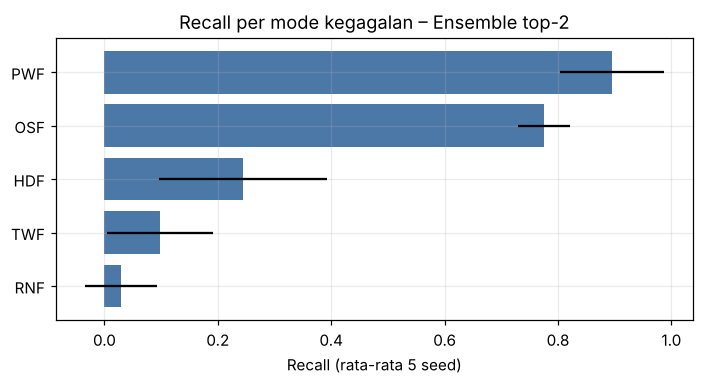

Rata-rata fitur menurut hasil deteksi (seed utama):


,air_temp,proc_temp,rpm,torque,tool_wear,temp_diff,power_w,wear_torque,n
hasil,,,,,,,,,
FN,301.4,310.4,1415.4,48.2,154.1,9.0,7001.2,7155.3,38
FP,298.9,309.0,1680.6,36.1,122.8,10.1,5834.7,4398.3,43
TN,300.0,310.0,1535.2,39.6,107.1,10.0,6242.7,4247.5,1889
TP,299.9,309.8,1560.9,52.6,152.4,9.8,7569.9,8022.6,30


In [24]:
# E4 Analisis galat per mode kegagalan dan per tipe produk (RQ3)
rec_rows, type_rows = [], []
for seed in SEEDS:
    s_val, s_te = cand_scores(FINAL_MEMBERS, seed)
    s_ = SPLITS[seed]
    thr = np.quantile(s_val, 1 - y[s_["tr_all"]].mean())
    te_df = d.iloc[s_["te"]].copy(); te_df["pred"] = (s_te > thr).astype(int)
    for m in MODES:
        sub = te_df[te_df[m] == 1]
        if len(sub):
            rec_rows.append(dict(seed=seed, mode=m.upper(), n=len(sub), recall=sub.pred.mean()))
    for tp_, sub in te_df.groupby("type"):
        type_rows.append(dict(seed=seed, type=tp_, recall=sub.loc[sub.machine_failure == 1, "pred"].mean(),
                              fpr=sub.loc[sub.machine_failure == 0, "pred"].mean()))
    sub0 = te_df[(te_df.machine_failure == 0)]
    rec_rows.append(dict(seed=seed, mode="NORMAL (alarm palsu)", n=len(sub0), recall=sub0.pred.mean()))
rec_mode = pd.DataFrame(rec_rows).groupby("mode").agg(n_rata2=("n", "mean"), recall=("recall", "mean"),
                                                       std=("recall", "std")).round(3)
display(rec_mode)
display(pd.DataFrame(type_rows).groupby("type")[["recall", "fpr"]].mean().round(3))

mode_only = rec_mode.drop(index="NORMAL (alarm palsu)").sort_values("recall")
plt.figure(figsize=(6.5, 3.6))
plt.barh(mode_only.index, mode_only.recall, xerr=mode_only["std"], color="#4c78a8")
plt.xlabel("Recall (rata-rata 5 seed)"); plt.title(f"Recall per mode kegagalan – {FINAL}")
plt.tight_layout(); savefig("w6_recall_per_mode"); plt.show()

# profil TP / FN / FP / TN (satuan asli, seed utama)
s_val, s_te = cand_scores(FINAL_MEMBERS, SEED)
s_ = SPLITS[SEED]; thr = np.quantile(s_val, 1 - y[s_["tr_all"]].mean())
te_df = d.iloc[s_["te"]].copy(); pr_ = (s_te > thr).astype(int)
te_df["hasil"] = np.select([(pr_ == 1) & (te_df.machine_failure == 1), (pr_ == 0) & (te_df.machine_failure == 1),
                            (pr_ == 1) & (te_df.machine_failure == 0)], ["TP", "FN", "FP"], "TN")
print("Rata-rata fitur menurut hasil deteksi (seed utama):")
display(te_df.groupby("hasil")[["air_temp", "proc_temp", "rpm", "torque", "tool_wear",
                                "temp_diff", "power_w", "wear_torque"]].mean().round(1).assign(n=te_df.hasil.value_counts()))

Model: One-Class SVM {'nu': 0.01, 'gamma': 0.03} | PR-AUC validasi dasar = 0.481


,penurunan_PR_AUC,std
fitur,,
rpm,0.2625,0.0248
wear_torque,0.1846,0.0052
power_w,0.1785,0.0164
torque,0.1258,0.0217
temp_diff,0.0683,0.0172
tool_wear,0.0434,0.0080
air_temp,0.0171,0.0107
type_ord,0.0111,0.0044
proc_temp,0.0049,0.0214


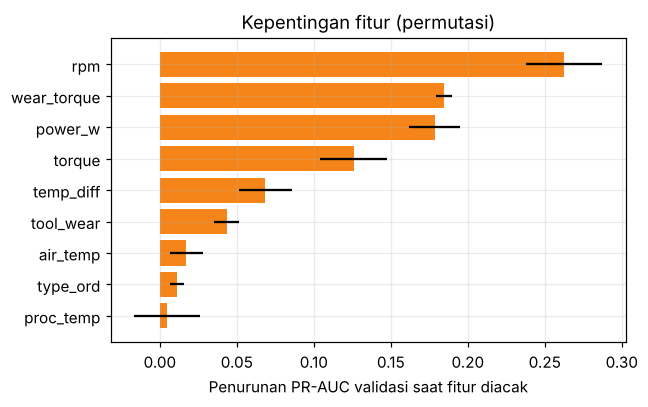

In [25]:
# E5 Kepentingan fitur (permutasi pada data validasi, model tunggal terbaik)
Xf, Xv, Xt = DATA[SEED]
feat_names = FEATS[BEST_FEAT]; yv = y[SPLITS[SEED]["val"]]
kw = BEST_PARAMS.get(BEST_SINGLE, {})
base = average_precision_score(yv, fit_score(BEST_SINGLE, Xf, Xv, Xt, SEED, **kw)[0])
rng = np.random.default_rng(SEED); imp = []
for j, f in enumerate(feat_names):
    drops = []
    for _ in range(5):
        Xp = Xv.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base - average_precision_score(yv, fit_score(BEST_SINGLE, Xf, Xp, Xt, SEED, **kw)[0]))
    imp.append(dict(fitur=f, penurunan_PR_AUC=np.mean(drops), std=np.std(drops)))
imp = pd.DataFrame(imp).set_index("fitur").sort_values("penurunan_PR_AUC", ascending=False).round(4)
print(f"Model: {BEST_SINGLE} {kw} | PR-AUC validasi dasar = {base:.3f}")
display(imp)
plt.figure(figsize=(6, 3.8))
plt.barh(imp.index[::-1], imp.penurunan_PR_AUC[::-1], xerr=imp["std"][::-1], color="#f58518")
plt.xlabel("Penurunan PR-AUC validasi saat fitur diacak"); plt.title("Kepentingan fitur (permutasi)")
plt.tight_layout(); savefig("w7_kepentingan_fitur"); plt.show()

In [26]:
# 5.x Tabel hasil eksperimen awal (gabungan, untuk laporan)
cfg = (res.fitur == BEST_FEAT) & (res.skenario == BEST_SCEN)
agg = lambda df_, key: df_.groupby(key)[["val_pr_auc"] + METRICS].agg(["mean", "std"])
def fmt(t):
    out = pd.DataFrame(index=t.index)
    for m in ["val_pr_auc"] + METRICS:
        out[m] = t[(m, "mean")].map("{:.3f}".format) + " ± " + t[(m, "std")].map("{:.3f}".format)
    return out
t_base = fmt(agg(res[cfg & res.model.isin(BASELINES)], "model")).assign(jenis="baseline", hiperparameter="-")
t_def = fmt(agg(res[cfg & res.model.isin(CANDIDATES)], "model")).assign(jenis="kandidat (bawaan)")
t_def["hiperparameter"] = [str(DEFAULTS[m]) if DEFAULTS[m] else "-" for m in t_def.index]
t_tun = fmt(agg(cand_df, "kandidat")).assign(jenis="kandidat (setelan awal)")
t_tun["hiperparameter"] = [str(BEST_PARAMS.get(k, "-")) if not k.startswith("Ensemble") else "rank-average: " + " + ".join(CAND[k])
                           for k in t_tun.index]
t_tun.index = [k if k.startswith("Ensemble") else f"{k} (setelan)" for k in t_tun.index]
tabel_hasil = pd.concat([t_base, t_def, t_tun])
tabel_hasil.insert(0, "jenis", tabel_hasil.pop("jenis"))
tabel_hasil.insert(1, "hiperparameter", tabel_hasil.pop("hiperparameter"))
tabel_hasil["validasi"] = f"hold-out stratified 60/20/20, 5 seed; fitur {BEST_FEAT}, skenario {BEST_SCEN}"
tabel_hasil.index.name = "model"
print("Nilai = rata-rata ± simpangan baku 5 seed. val_pr_auc = PR-AUC validasi; kolom lain = data uji.")
display(tabel_hasil.drop(columns="validasi"))

# ringkasan ablasi (E1) dan recall per tipe (E4) untuk ditelusuri dari laporan
abl = summ(d1).add_prefix("ENG_minus_RAW_").join(summ(d2).add_prefix("semi_minus_unsup_"))
type_tab = pd.DataFrame(type_rows).groupby("type")[["recall", "fpr"]].mean().round(3)
cfg_tab = cfg_val.round(3).rename("val_pr_auc_rata2").reset_index()
base_tab = res_base.groupby(["model", "fitur", "skenario"])[METRICS].agg(["mean", "std"]).round(3)
pivot_pr = res.pivot_table(index="model", columns=["fitur", "skenario"], values="pr_auc").loc[MODEL_NAMES].round(3)

Nilai = rata-rata ± simpangan baku 5 seed. val_pr_auc = PR-AUC validasi; kolom lain = data uji.


,jenis,hiperparameter,val_pr_auc,roc_auc,pr_auc,precision,recall,f1
model,,,,,,,,
Acak (baseline),baseline,-,0.036 ± 0.006,0.493 ± 0.040,0.042 ± 0.011,0.049 ± 0.007,0.050 ± 0.008,0.050 ± 0.008
Z-score maks (baseline),baseline,-,0.291 ± 0.033,0.860 ± 0.030,0.310 ± 0.079,0.379 ± 0.083,0.376 ± 0.101,0.376 ± 0.088
Autoencoder (MLP),kandidat (bawaan),"{'hidden': (16, 3, 16), 'alpha': 0.0001}",0.043 ± 0.007,0.613 ± 0.062,0.049 ± 0.009,0.032 ± 0.021,0.035 ± 0.027,0.033 ± 0.023
Isolation Forest,kandidat (bawaan),"{'n_estimators': 300, 'max_samples': 'auto', '...",0.230 ± 0.027,0.871 ± 0.024,0.274 ± 0.081,0.291 ± 0.045,0.332 ± 0.105,0.306 ± 0.063
LOF,kandidat (bawaan),{'n_neighbors': 35},0.454 ± 0.020,0.901 ± 0.018,0.464 ± 0.056,0.447 ± 0.048,0.503 ± 0.079,0.470 ± 0.052
Mahalanobis,kandidat (bawaan),-,0.298 ± 0.038,0.876 ± 0.027,0.334 ± 0.090,0.365 ± 0.067,0.382 ± 0.106,0.371 ± 0.079
One-Class SVM,kandidat (bawaan),"{'nu': 0.05, 'gamma': 'scale'}",0.422 ± 0.029,0.873 ± 0.031,0.434 ± 0.085,0.408 ± 0.067,0.459 ± 0.081,0.429 ± 0.060
PCA reconstruction,kandidat (bawaan),{'n_components': 0.95},0.236 ± 0.046,0.792 ± 0.035,0.252 ± 0.070,0.304 ± 0.068,0.294 ± 0.098,0.293 ± 0.075
Autoencoder (MLP) (setelan),kandidat (setelan awal),"{'hidden': (16, 6, 16), 'alpha': 0.0001}",0.301 ± 0.070,0.808 ± 0.040,0.334 ± 0.081,0.353 ± 0.063,0.362 ± 0.090,0.354 ± 0.070


**Catatan Minggu 5–7:**
- **E1 (RQ1, fitur turunan):** rata-rata ΔPR-AUC (ENG − RAW) = **+0,053**, menang pada 72% pasangan. Peningkatan konsisten 10/10 pasangan pada Isolation Forest (+0,138), LOF (+0,107), One-Class SVM (+0,077), dan Mahalanobis (+0,055). Sebaliknya PCA reconstruction (−0,032, 0/10) dan Autoencoder (−0,026, 3/10) **memburuk** — model rekonstruksi justru mudah merekonstruksi fitur turunan yang merupakan fungsi dari fitur lain. Jadi H1 **didukung untuk model jarak/kepadatan/pohon, tidak untuk model rekonstruksi**.
- **E1 (RQ2, latih data normal):** rata-rata ΔPR-AUC (semi − unsup) = **+0,049** (menang 73%). Keuntungan besar hanya pada LOF (+0,152) dan One-Class SVM (+0,118), yang batas/kepadatannya mudah "tertarik" oleh anomali di data latih. Isolation Forest sedikit memburuk (−0,014, 1/10); model lain hampir tidak berubah. Secara rata-rata H2 **didukung**, tetapi efeknya **tidak merata** antar-model.
- **E2 (penyetelan awal):** model yang paling diuntungkan adalah Autoencoder (PR-AUC validasi 0,043 → 0,301 setelah bottleneck diperbesar ke 6) — kegagalan di Minggu 4 disebabkan konfigurasi, bukan metodenya. Isolation Forest (0,230 → 0,307), PCA (0,236 → 0,302), dan One-Class SVM (0,422 → 0,464) naik; LOF tetap (n_neighbors = 35 sudah optimum, kurva sensitivitas berbentuk punuk). **Lima parameter terbaik berada di tepi grid** (PCA, IF ×2, OCSVM nu, AE alpha) → grid perlu diperluas pada tahap UAS.
- **E3 (ensemble):** Ensemble top-2 (One-Class SVM + LOF) terbaik di validasi (0,480) dan di uji (PR-AUC 0,486 ± 0,066). Namun selisihnya terhadap One-Class SVM tunggal hanya +0,020, **lebih kecil dari simpangan baku antar-seed (0,071)**, sehingga belum dapat disimpulkan lebih baik secara andal. Menambah anggota (top-3/top-4) tidak membantu.
- **E4 (RQ3, analisis galat):** recall per mode — PWF 0,895, OSF 0,776, HDF 0,245, TWF 0,098, RNF 0,029; alarm palsu 2,2% dari siklus normal. TWF dan RNF sulit sesuai dugaan (tidak punya aturan deterministik). **Temuan mengejutkan: HDF juga sulit** padahal aturannya deterministik. Penjelasannya: HDF terjadi ketika *dua* syarat terpenuhi bersamaan (`temp_diff` < 8,6 K **dan** rpm < 1380), tetapi masing-masing nilai itu sendiri tidak ekstrem (6% siklus normal juga punya `temp_diff` < 8,6 K). Detektor anomali mencari titik yang *jauh dari massa data*, bukan titik di sudut kombinasi tertentu. Profil FN mendukung ini: rata-rata rpm FN 1415 (rendah) dan `temp_diff` 9,0 K.
- **E5 (kepentingan fitur, One-Class SVM):** fitur paling berpengaruh adalah rpm (−0,263 PR-AUC jika diacak), `wear_torque` (−0,185), dan `power_w` (−0,179). Dua dari tiga adalah fitur turunan, konsisten dengan E1. `proc_temp` hampir tidak berpengaruh.

---
# UTS · Milestone 1
Pencapaian target pertama: masalah terumuskan, data dipahami dan diproses, baseline ditetapkan, kandidat dibandingkan, dan eksperimen awal dikembangkan.

In [27]:
# 6.1 Checklist capaian per tahap
def done(*names): return "✔" if all(n in globals() for n in names) else "✘"
checklist = pd.DataFrame([
    ("Minggu 1", "Problem Formulation", "Rumusan masalah, RQ, hipotesis, definisi anomali, metrik", done("PROJECT")),
    ("Minggu 2", "Data Understanding & Preprocessing", "EDA, verifikasi aturan, fitur turunan, cek kebocoran", done("FEATS", "eff")),
    ("Minggu 3", "Baseline & Evaluasi Awal", "Split 60/20/20, 5 seed, baseline Acak dan Z-score", done("res_base", "SPLITS")),
    ("Minggu 4", "Kandidat Model & Perbandingan", "6 model, 2 fitur, 2 skenario, shortlist dari validasi", done("res", "SHORTLIST")),
    ("Minggu 5–7", "Eksperimen Awal", "Ablasi, penyetelan awal, ensemble, analisis galat, kepentingan fitur", done("tune_report", "FINAL", "rec_mode", "imp")),
    ("UTS", "Milestone 1", "Tabel hasil eksperimen awal, ringkasan, keterbatasan, rencana UAS", done("tabel_hasil")),
], columns=["Tahap", "Nama", "Isi", "Status"]).set_index("Tahap")
display(checklist)

,Nama,Isi,Status
Tahap,,,
Minggu 1,Problem Formulation,"Rumusan masalah, RQ, hipotesis, definisi anoma...",✔
Minggu 2,Data Understanding & Preprocessing,"EDA, verifikasi aturan, fitur turunan, cek keb...",✔
Minggu 3,Baseline & Evaluasi Awal,"Split 60/20/20, 5 seed, baseline Acak dan Z-score",✔
Minggu 4,Kandidat Model & Perbandingan,"6 model, 2 fitur, 2 skenario, shortlist dari v...",✔
Minggu 5–7,Eksperimen Awal,"Ablasi, penyetelan awal, ensemble, analisis ga...",✔
UTS,Milestone 1,"Tabel hasil eksperimen awal, ringkasan, keterb...",✔


In [28]:
# 6.2 Ringkasan temuan (dihitung otomatis dari output)
def mean_of(model, col="pr_auc"):
    s = res[(res.model == model) & (res.fitur == BEST_FEAT) & (res.skenario == BEST_SCEN)]
    return s[col].mean()

base_best = max(BASELINES, key=lambda m: mean_of(m))
best_default = rank.index[0]
fm = FINAL_STATS.loc["mean"]; fs = FINAL_STATS.loc["std"]

mode_rec = rec_mode.drop(index="NORMAL (alarm palsu)").recall.sort_values()
low2 = set(mode_rec.index[:2])
h3 = "didukung" if low2 == {"TWF", "RNF"} else ("didukung sebagian" if low2 & {"TWF", "RNF"} else "tidak didukung")
easy_low = {m: v for m, v in mode_rec.items() if m in {"PWF", "HDF", "OSF"} and v < 0.30}
if easy_low:
    h3 += " (namun " + ", ".join(f"{m} juga rendah: {v:.0%}" for m, v in easy_low.items()) + ", tidak sesuai dugaan 'mudah')"
verdict = lambda x: "didukung" if x > 0 else "tidak didukung"
false_alarm = rec_mode.loc["NORMAL (alarm palsu)", "recall"]

print("RINGKASAN TEMUAN MILESTONE 1")
print("=" * 70)
print(f"1. Data: {len(d)} siklus, {int(y.sum())} gagal ({y.mean():.2%}); {n_f1_nomode + n_mode_f0} baris berlabel tidak konsisten.")
print(f"2. Baseline terbaik: {base_best} dengan PR-AUC {mean_of(base_best):.3f} (acak ≈ {prev:.3f}).")
print(f"3. Konfigurasi terpilih lewat validasi: fitur {BEST_FEAT}, skenario {BEST_SCEN}.")
print(f"   Model bawaan terbaik: {best_default} (PR-AUC uji {mean_of(best_default):.3f}).")
print(f"4. Setelah penyetelan awal + ensemble, kandidat terbaik sementara (dipilih lewat validasi): {FINAL}")
print(f"   PR-AUC uji {fm.pr_auc:.3f} ± {fs.pr_auc:.3f} | ROC-AUC {fm.roc_auc:.3f} | precision {fm.precision:.3f} | "
      f"recall {fm.recall:.3f} | F1 {fm.f1:.3f}")
print(f"   Selisih terhadap baseline terbaik: {fm.pr_auc - mean_of(base_best):+.3f} PR-AUC.")
print(f"5. RQ1/H1 (fitur turunan): rata-rata ΔPR-AUC {H1_MEAN:+.3f}, menang {H1_WIN:.0%} pasangan → {verdict(H1_MEAN)}.")
print(f"   RQ2/H2 (latih data normal): rata-rata ΔPR-AUC {H2_MEAN:+.3f}, menang {H2_WIN:.0%} pasangan → {verdict(H2_MEAN)}.")
print(f"   RQ3/H3 (mode sulit): recall terendah {', '.join(f'{m} {v:.0%}' for m, v in mode_rec.head(3).items())}; "
      f"tertinggi {mode_rec.index[-1]} {mode_rec.iloc[-1]:.0%} → H3 {h3}.")
print(f"6. Alarm palsu pada data normal ≈ {false_alarm:.1%}.")
single_te = cand_df[cand_df.kandidat == BEST_SINGLE].pr_auc
gap = fm.pr_auc - single_te.mean()
if FINAL != BEST_SINGLE:
    sig = "lebih kecil" if abs(gap) < single_te.std() else "lebih besar"
    print(f"7. Kandidat terbaik vs model tunggal terbaik ({BEST_SINGLE}): selisih PR-AUC uji {gap:+.3f}, {sig} dari simpangan baku antar-seed "
          f"({single_te.std():.3f}) → {'belum dapat disimpulkan lebih baik secara andal' if sig == 'lebih kecil' else 'perbaikan cukup jelas'}.")
print(f"8. Fitur paling berpengaruh pada {BEST_SINGLE}: {', '.join(imp.index[:3])}.")

RINGKASAN TEMUAN MILESTONE 1
1. Data: 10000 siklus, 339 gagal (3.39%); 27 baris berlabel tidak konsisten.
2. Baseline terbaik: Z-score maks (baseline) dengan PR-AUC 0.310 (acak ≈ 0.034).
3. Konfigurasi terpilih lewat validasi: fitur ENG, skenario semi.
   Model bawaan terbaik: LOF (PR-AUC uji 0.464).
4. Setelah penyetelan awal + ensemble, kandidat terbaik sementara (dipilih lewat validasi): Ensemble top-2
   PR-AUC uji 0.486 ± 0.066 | ROC-AUC 0.909 | precision 0.442 | recall 0.488 | F1 0.462
   Selisih terhadap baseline terbaik: +0.176 PR-AUC.
5. RQ1/H1 (fitur turunan): rata-rata ΔPR-AUC +0.053, menang 72% pasangan → didukung.
   RQ2/H2 (latih data normal): rata-rata ΔPR-AUC +0.049, menang 73% pasangan → didukung.
   RQ3/H3 (mode sulit): recall terendah RNF 3%, TWF 10%, HDF 24%; tertinggi PWF 90% → H3 didukung (namun HDF juga rendah: 24%, tidak sesuai dugaan 'mudah').
6. Alarm palsu pada data normal ≈ 2.2%.
7. Kandidat terbaik vs model tunggal terbaik (One-Class SVM): selisih PR-AUC uj

In [29]:
# 6.3 Simpan semua hasil
res.to_csv(OUT / "hasil_perbandingan_model.csv", index=False)
tune.to_csv(OUT / "hasil_tuning.csv", index=False)
tune_report.to_csv(OUT / "ringkasan_tuning.csv")
cand_df.to_csv(OUT / "hasil_kandidat_akhir.csv", index=False)
rec_mode.to_csv(OUT / "recall_per_mode.csv")
imp.to_csv(OUT / "kepentingan_fitur.csv")
tabel_hasil.to_csv(OUT / "tabel_hasil_eksperimen_awal.csv")
abl.to_csv(OUT / "ablasi_rq1_rq2.csv")
type_tab.to_csv(OUT / "recall_per_tipe.csv")
cfg_tab.to_csv(OUT / "pemilihan_konfigurasi_validasi.csv", index=False)
base_tab.to_csv(OUT / "hasil_baseline_ringkas.csv")
pivot_pr.to_csv(OUT / "pr_auc_uji_per_konfigurasi.csv")
json.dump({"catatan": "kandidat terbaik sementara Milestone 1 (bukan model final proyek)", "model_akhir": FINAL, "anggota": FINAL_MEMBERS, "fitur": BEST_FEAT, "skenario": BEST_SCEN,
           "param": {k: str(v) for k, v in BEST_PARAMS.items()},
           "uji_mean": fm.to_dict(), "uji_std": fs.to_dict()},
          open(OUT / "ringkasan_model_akhir.json", "w"), indent=2, ensure_ascii=False)
print("File tersimpan di folder 'outputs':", sorted(p.name for p in OUT.iterdir()))

File tersimpan di folder 'outputs': ['ablasi_rq1_rq2.csv', 'data_preprocessed.csv', 'figures', 'hasil_baseline_ringkas.csv', 'hasil_kandidat_akhir.csv', 'hasil_perbandingan_model.csv', 'hasil_tuning.csv', 'kepentingan_fitur.csv', 'pemilihan_konfigurasi_validasi.csv', 'pr_auc_uji_per_konfigurasi.csv', 'recall_per_mode.csv', 'recall_per_tipe.csv', 'ringkasan_model_akhir.json', 'ringkasan_tuning.csv', 'tabel_hasil_eksperimen_awal.csv']


## 6.4 Refleksi
1. **Temuan utama:** dengan fitur turunan dan pelatihan hanya pada data normal (ENG-semi), kandidat terbaik sementara adalah **Ensemble top-2 (One-Class SVM + LOF)** dengan PR-AUC uji **0,486 ± 0,066**, ROC-AUC 0,909, precision 0,442, recall 0,488, F1 0,462. Ini **+0,176 PR-AUC** di atas baseline terbaik (Z-score maks, 0,310) dan ±14× skor acak. RQ1 didukung untuk model jarak/kepadatan/pohon (bukan model rekonstruksi); RQ2 didukung terutama untuk LOF dan One-Class SVM; RQ3: TWF dan RNF memang sulit, tetapi HDF ternyata juga sulit.
2. **Hal yang mengejutkan:** (a) Autoencoder dengan konfigurasi bawaan hampir setara skor acak, lalu naik drastis setelah bottleneck diperbesar; (b) HDF yang aturannya deterministik hanya terdeteksi ±25%; (c) model rekonstruksi (PCA, Autoencoder) justru memburuk dengan fitur turunan.
3. **Penjelasan:** PWF dan OSF mudah karena keduanya didefinisikan oleh nilai **ekstrem** (daya di luar 3.500–9.000 W, keausan×torsi di atas batas) — persis yang dicari detektor anomali. HDF adalah kombinasi dua kondisi yang masing-masing tidak ekstrem, sehingga titiknya tidak jauh dari massa data normal. RNF (peluang acak 0,1%) secara definisi tidak bergantung pada parameter proses, jadi mustahil dideteksi dari fitur.
4. **Harga tanpa label:** pada data normal, alarm palsu hanya ±2,2%, tetapi lebih dari separuh kegagalan masih lolos. Hal ini menjadi fokus pengembangan menuju UAS.

## 6.5 Keterbatasan
- **Data sintetis** dan aturan kegagalannya diketahui → hasil tidak otomatis berlaku di pabrik nyata.
- Fitur turunan (`power_w`, `wear_torque`, `temp_diff`) mengodekan aturan pembangkitan kegagalan dari dokumentasi dataset, sehingga sebagian keunggulannya merupakan "kebocoran pengetahuan domain". Ini sah (pengetahuan domain tersedia sebelum pemodelan), tetapi harus dinyatakan.
- Statistik EDA (Cohen's d, verifikasi aturan) dihitung pada seluruh data, termasuk calon data uji; hanya dipakai untuk pemahaman dan desain fitur, bukan untuk pelatihan.
- Data validasi dipakai untuk beberapa keputusan sekaligus (konfigurasi, hiperparameter, anggota ensemble, kandidat terbaik, ambang) → ada risiko *overfitting* ke validasi. Data uji tetap tidak disentuh untuk keputusan apa pun.
- Normalisasi peringkat pada ensemble memakai gabungan skor validasi dan uji tanpa label (transduktif).
- Ambang memakai prior kegagalan dari data latih (butuh label untuk menghitung proporsi), yang pada praktik nyata belum tentu diketahui.
- Baris diperlakukan independen; data asli memiliki urutan waktu dan keausan yang berevolusi.
- Penyetelan hanya pada satu konfigurasi (ENG-semi) dan memakai grid kecil; lima parameter terbaik berada di tepi grid.
- Hanya satu definisi anomali (`machine_failure`); 27 baris berlabel tidak konsisten belum diperlakukan khusus.
- Selisih antar-model teratas (Ensemble top-2 vs One-Class SVM vs LOF) lebih kecil dari simpangan baku antar-seed; belum ada uji signifikansi.

## 6.6 Rencana setelah UTS (menuju UAS)
| Minggu | Pekerjaan | Dasar (temuan Milestone 1) |
|---|---|---|
| 9–10 | Validasi silang berulang (repeated stratified K-fold) dan uji Wilcoxon berpasangan antar-model teratas | selisih Ensemble/OCSVM/LOF < simpangan baku antar-seed |
| 9–10 | Perluas grid hiperparameter (PCA, IF, OCSVM `nu` < 0,01, AE `alpha`) dan setel juga konfigurasi RAW/unsup | 5 parameter terbaik di tepi grid |
| 10–11 | Ensemble non-transduktif: peringkat skor uji terhadap distribusi skor validasi saja | keterbatasan normalisasi peringkat |
| 10–11 | Tangani 27 baris label tidak konsisten (bandingkan: dibuang vs anomali = gabungan mode) | inkonsistensi label di bagian 2.3 |
| 11–12 | Fitur tambahan untuk HDF (mis. jarak ke batas `temp_diff` = 8,6 K dan rpm = 1380, interaksi) dan detektor per mode | recall HDF hanya 0,245 |
| 12 | Sensitivitas ambang & ambang berbasis biaya (bobot FN vs FP); ambang tanpa prior berlabel | ambang saat ini bergantung prior kegagalan |
| 13 | Batas atas klasifikasi berlabel (mis. HistGradientBoosting) sebagai pembanding "harga tanpa label"; pengaruh ukuran data latih normal | kebutuhan label & data di praktik |
| 14 | Pemilihan model final, analisis galat lengkap, laporan akhir & presentasi | — |

Semua metode tetap dalam lingkup *classical machine learning* (scikit-learn).

## 6.7 Referensi (format IEEE)
Penomoran sama dengan daftar pustaka pada laporan PDF.

[1] R. K. Mobley, *An Introduction to Predictive Maintenance*, 2nd ed. Amsterdam, The Netherlands: Butterworth-Heinemann, 2002.<br>
[2] A. K. S. Jardine, D. Lin, and D. Banjevic, "A review on machinery diagnostics and prognostics implementing condition-based maintenance," *Mech. Syst. Signal Process.*, vol. 20, no. 7, pp. 1483–1510, Oct. 2006, doi: 10.1016/j.ymssp.2005.09.012.<br>
[3] T. P. Carvalho, F. A. A. M. N. Soares, R. Vita, R. da P. Francisco, J. P. Basto, and S. G. S. Alcalá, "A systematic literature review of machine learning methods applied to predictive maintenance," *Comput. Ind. Eng.*, vol. 137, Art. no. 106024, Nov. 2019, doi: 10.1016/j.cie.2019.106024.<br>
[4] T. Zonta, C. A. da Costa, R. da Rosa Righi, M. J. de Lima, E. S. da Trindade, and G. P. Li, "Predictive maintenance in the Industry 4.0: A systematic literature review," *Comput. Ind. Eng.*, vol. 150, Art. no. 106889, Dec. 2020, doi: 10.1016/j.cie.2020.106889.<br>
[5] H. He and E. A. Garcia, "Learning from imbalanced data," *IEEE Trans. Knowl. Data Eng.*, vol. 21, no. 9, pp. 1263–1284, Sep. 2009, doi: 10.1109/TKDE.2008.239.<br>
[6] V. Chandola, A. Banerjee, and V. Kumar, "Anomaly detection: A survey," *ACM Comput. Surv.*, vol. 41, no. 3, Art. no. 15, pp. 1–58, Jul. 2009, doi: 10.1145/1541880.1541882.<br>
[7] M. A. F. Pimentel, D. A. Clifton, L. Clifton, and L. Tarassenko, "A review of novelty detection," *Signal Process.*, vol. 99, pp. 215–249, Jun. 2014, doi: 10.1016/j.sigpro.2013.12.026.<br>
[8] C. C. Aggarwal, *Outlier Analysis*, 2nd ed. Cham, Switzerland: Springer, 2017, doi: 10.1007/978-3-319-47578-3.<br>
[9] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.<br>
[10] S. Matzka, "Explainable artificial intelligence for predictive maintenance applications," in *Proc. 3rd Int. Conf. Artif. Intell. Ind. (AI4I)*, Irvine, CA, USA, 2020, pp. 69–74, doi: 10.1109/AI4I49448.2020.00023.<br>
[11] S. Matzka, "AI4I 2020 predictive maintenance dataset," UCI Machine Learning Repository, 2020. [Online]. Available: https://archive.ics.uci.edu/dataset/601, doi: 10.24432/C5HS5C.<br>
[12] J. W. Tukey, *Exploratory Data Analysis*. Reading, MA, USA: Addison-Wesley, 1977.<br>
[13] J. Cohen, *Statistical Power Analysis for the Behavioral Sciences*, 2nd ed. Hillsdale, NJ, USA: Lawrence Erlbaum Associates, 1988.<br>
[14] S. Kaufman, S. Rosset, C. Perlich, and O. Stitelman, "Leakage in data mining: Formulation, detection, and avoidance," *ACM Trans. Knowl. Discov. Data*, vol. 6, no. 4, Art. no. 15, pp. 1–21, Dec. 2012, doi: 10.1145/2382577.2382579.<br>
[15] P. C. Mahalanobis, "On the generalised distance in statistics," *Proc. Nat. Inst. Sci. India*, vol. 2, no. 1, pp. 49–55, 1936.<br>
[16] I. T. Jolliffe, *Principal Component Analysis*, 2nd ed. New York, NY, USA: Springer, 2002, doi: 10.1007/b98835.<br>
[17] H. Hoffmann, "Kernel PCA for novelty detection," *Pattern Recognit.*, vol. 40, no. 3, pp. 863–874, Mar. 2007, doi: 10.1016/j.patcog.2006.07.009.<br>
[18] F. T. Liu, K. M. Ting, and Z.-H. Zhou, "Isolation forest," in *Proc. 8th IEEE Int. Conf. Data Mining (ICDM)*, Pisa, Italy, 2008, pp. 413–422, doi: 10.1109/ICDM.2008.17.<br>
[19] M. M. Breunig, H.-P. Kriegel, R. T. Ng, and J. Sander, "LOF: Identifying density-based local outliers," in *Proc. ACM SIGMOD Int. Conf. Manage. Data*, Dallas, TX, USA, 2000, pp. 93–104, doi: 10.1145/342009.335388.<br>
[20] B. Schölkopf, J. C. Platt, J. Shawe-Taylor, A. J. Smola, and R. C. Williamson, "Estimating the support of a high-dimensional distribution," *Neural Comput.*, vol. 13, no. 7, pp. 1443–1471, Jul. 2001, doi: 10.1162/089976601750264965.<br>
[21] G. E. Hinton and R. R. Salakhutdinov, "Reducing the dimensionality of data with neural networks," *Science*, vol. 313, no. 5786, pp. 504–507, Jul. 2006, doi: 10.1126/science.1127647.<br>
[22] M. Sakurada and T. Yairi, "Anomaly detection using autoencoders with nonlinear dimensionality reduction," in *Proc. 2nd Workshop Mach. Learn. Sensory Data Anal. (MLSDA)*, Gold Coast, QLD, Australia, 2014, pp. 4–11, doi: 10.1145/2689746.2689747.<br>
[23] R. Kohavi, "A study of cross-validation and bootstrap for accuracy estimation and model selection," in *Proc. 14th Int. Joint Conf. Artif. Intell. (IJCAI)*, Montreal, QC, Canada, 1995, pp. 1137–1143.<br>
[24] T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets," *PLoS ONE*, vol. 10, no. 3, Art. no. e0118432, Mar. 2015, doi: 10.1371/journal.pone.0118432.<br>
[25] J. Davis and M. Goadrich, "The relationship between precision-recall and ROC curves," in *Proc. 23rd Int. Conf. Mach. Learn. (ICML)*, Pittsburgh, PA, USA, 2006, pp. 233–240, doi: 10.1145/1143844.1143874.<br>
[26] G. O. Campos *et al.*, "On the evaluation of unsupervised outlier detection: Measures, datasets, and an empirical study," *Data Min. Knowl. Discov.*, vol. 30, no. 4, pp. 891–927, Jul. 2016, doi: 10.1007/s10618-015-0444-8.<br>
[27] J. Bergstra and Y. Bengio, "Random search for hyper-parameter optimization," *J. Mach. Learn. Res.*, vol. 13, pp. 281–305, Feb. 2012.<br>
[28] C. C. Aggarwal and S. Sathe, "Theoretical foundations and algorithms for outlier ensembles," *ACM SIGKDD Explor. Newsl.*, vol. 17, no. 1, pp. 24–47, Jun. 2015, doi: 10.1145/2830544.2830549.<br>
[29] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, Oct. 2001, doi: 10.1023/A:1010933404324.<br>
[30] G. C. Cawley and N. L. C. Talbot, "On over-fitting in model selection and subsequent selection bias in performance evaluation," *J. Mach. Learn. Res.*, vol. 11, pp. 2079–2107, Jul. 2010.<br>
[31] C. R. Harris *et al.*, "Array programming with NumPy," *Nature*, vol. 585, no. 7825, pp. 357–362, Sep. 2020, doi: 10.1038/s41586-020-2649-2.<br>
[32] W. McKinney, "Data structures for statistical computing in Python," in *Proc. 9th Python Sci. Conf. (SciPy)*, Austin, TX, USA, 2010, pp. 56–61, doi: 10.25080/Majora-92bf1922-00a.<br>
[33] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Comput. Sci. Eng.*, vol. 9, no. 3, pp. 90–95, May/Jun. 2007, doi: 10.1109/MCSE.2007.55.<br>
[34] P. Virtanen *et al.*, "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nat. Methods*, vol. 17, no. 3, pp. 261–272, Mar. 2020, doi: 10.1038/s41592-019-0686-2.<br>
[35] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, Dec. 1945, doi: 10.2307/3001968.<br>
[36] J. Demšar, "Statistical comparisons of classifiers over multiple data sets," *J. Mach. Learn. Res.*, vol. 7, pp. 1–30, Jan. 2006.<br>
[37] J. H. Friedman, "Greedy function approximation: A gradient boosting machine," *Ann. Statist.*, vol. 29, no. 5, pp. 1189–1232, Oct. 2001, doi: 10.1214/aos/1013203451.<br>